# Búsqueda y selección de modelos

Este notebook desarrolla el objetivo específico 2 del proyecto: desarrollar y comparar modelos de estimación ordinal del SII basados en indicadores físicos y demográficos, frente a un modelo de referencia, mediante validación cruzada estratificada y el QWK. Se comparan cuatro algoritmos —un modelo lineal regularizado, una SVM con kernel radial, un bosque aleatorio y gradient boosting— en tres formulaciones del SII —clasificación multiclase, descomposición ordinal de Frank y Hall y regresión con umbrales—, con la estrategia de tratamiento de los faltantes y la ponderación de los niveles como hiperparámetros de la validación interna.

El análisis exploratorio (`01_eda.ipynb`) definió el conjunto analítico: los participantes con SII registrado, las reglas de limpieza de valores inválidos, las variables excluidas por cobertura o redundancia, el resumen de la actigrafía y cuatro conjuntos anidados de predictores (referencia, principal sin actigrafía, principal y complementario). Los experimentos iniciales (`02_experimentos_iniciales.ipynb`) evaluaron dos configuraciones fijas en la formulación multiclase: no mostraron evidencia de mejora del conjunto principal frente a la referencia (H2) ni de la actigrafía (H3), y las dos configuraciones trataron el nivel severo de forma opuesta. Por eso la búsqueda completa amplía los algoritmos, las formulaciones y la ponderación, y vuelve a evaluar H2 y H3 con la configuración que resulte seleccionada.

El notebook se organiza así:

1. Datos y conjuntos de variables.
2. Diseño de la búsqueda.
3. Estimación del costo de cómputo.
4. Búsqueda completa.
5. Hiperparámetros elegidos y revisión de los bordes de la grilla.
6. Selección de la configuración.
7. Desempeño por nivel de la configuración seleccionada.
8. H2 y H3 con la configuración seleccionada.
9. Comparación en la subpoblación con actigrafía.
10. Configuración guardada y conclusiones.

In [1]:
import os
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from sklearn.dummy import DummyClassifier
from threadpoolctl import threadpool_info

from piu_severity.config import (
    FIGURES_DIR,
    INTERIM_DATA_DIR,
    PROJECT_ROOT,
    RANDOM_SEED,
    TABLES_DIR,
)
from piu_severity.data.clean import clean_values
from piu_severity.data.load import list_actigraphy_ids, load_train
from piu_severity.evaluation.inference import (
    SEVERE_LEVEL,
    SEVERE_RECALL_MAX_SD,
    assigned_level_distribution,
    holm_adjust,
    level_hits_by_repeat,
    mcnemar_by_repeat,
    negligibility_test,
    paired_participant_test,
    participant_bootstrap_ci,
    participant_hit_rates,
)
from piu_severity.evaluation.metrics import SII_LEVELS, as_levels
from piu_severity.evaluation.persistence import (
    CACHE_VERSION,
    cached_size,
    clear_pipeline_memory,
    directory_size,
    run_configurations_cached,
)
from piu_severity.evaluation.selection import (
    EDGE_RULE_MIN_FOLDS,
    HOLM_FAMILIES,
    MINIMUM_RELEVANT_QWK_DIFFERENCE,
    SELECTION_ALPHA,
    UNDERESTIMATION_TIE_TOLERANCE,
    apply_selection_rule,
    chosen_value_counts,
    compare_with_best,
    edge_review,
    grid_extension,
    most_frequent_value,
    parameter_short_name,
    selected_configuration,
)
from piu_severity.evaluation.validation import (
    N_INNER_SPLITS,
    N_OUTER_REPEATS,
    N_OUTER_SPLITS,
    aggregate_repeats,
    outer_splits,
    paired_differences,
    run_nested_cv,
    split_level_counts,
    summarize_by_repeat,
    summarize_paired,
)
from piu_severity.features.actigraphy import (
    load_actigraphy_summary,
    usable_actigraphy_mask,
)
from piu_severity.features.build import build_analytic_dataset
from piu_severity.features.groups import (
    TARGET_COLUMN,
    actigraphy_subset_feature_sets,
    experiment_feature_sets,
    is_excluded,
    is_instrument_season,
)
from piu_severity.models.pipelines import (
    ALGORITHMS,
    BOOSTING_MAX_ITER,
    BOOSTING_N_ITER_NO_CHANGE,
    BOOSTING_VALIDATION_FRACTION,
    CONVERGENCE_WARNING_MAX_SHARE,
    CUT_BOOSTING_RANDOM_CANDIDATES,
    CUT_FOREST_N_ESTIMATORS,
    EXECUTION_POOLS,
    FOREST_CORES_PER_WORKER,
    FOREST_N_ESTIMATORS,
    FORMULATIONS,
    LINEAR_MAX_ITER,
    MAX_CUT_LEVEL,
    MAX_ITER_INCREASE,
    MEMORY_BUDGET_FRACTION,
    MEMORY_SAFETY_FACTOR,
    MODELS_PER_PIPELINE_FIT,
    RESERVED_CORES,
    SEARCH_BUDGET_HOURS,
    available_workers,
    choose_cut_level,
    complexity_key,
    convergence_warning_share,
    cost_ratio,
    make_search_task,
    max_iter_factor_for,
    memory_budget_gb,
    n_candidates,
    n_forest_trees,
    pool_workers,
    project_search_hours,
    search_grid,
    total_memory_gb,
    workers_within_memory,
)
from piu_severity.models.registry import save_record, task_entry
from piu_severity.visualization.figures import save_figure

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
sns.set_theme(style="whitegrid")

# Figuras del notebook y carpetas de los dos cachés. Ambas carpetas están bajo
# data/interim, que git ignora, porque guardan datos transformados y predicciones
# por participante.
FIGURAS = FIGURES_DIR / "03_busqueda_modelos"
CARPETA_NOTEBOOK = INTERIM_DATA_DIR / "03_busqueda_modelos"
# Caché de resultados: un archivo por configuración, conjunto, repetición y partición.
CARPETA_CACHE = CARPETA_NOTEBOOK / "cache"
# Caché de Pipeline(memory=...): evita reajustar el preprocesamiento entre candidatos.
# Incluye la versión del caché porque joblib no detecta cambios en el código propio.
CARPETA_MEMORIA = CARPETA_NOTEBOOK / "pipeline_memory" / f"v{CACHE_VERSION}"

# Con True se recalculan todas las evaluaciones aunque exista un resultado válido.
RECALCULAR = False

# Recursos del equipo en el que se ejecuta el notebook: los procesos en paralelo
# y el presupuesto de memoria se calculan a partir de ellos.
N_NUCLEOS = os.cpu_count()
MEMORIA_TOTAL_GB = total_memory_gb()

NIVELES_SII = {0: "ninguno", 1: "leve", 2: "moderado", 3: "severo"}
NOMBRES_CONJUNTOS = {
    "reference": "referencia",
    "reference_with_actigraphy": "referencia con actigrafía",
    "main_without_actigraphy": "principal sin actigrafía",
    "main": "principal",
    "complementary": "complementario",
}
NOMBRES_ALGORITMOS = {
    "linear": "lineal regularizado",
    "svm": "SVM con kernel radial",
    "random_forest": "bosque aleatorio",
    "gradient_boosting": "gradient boosting",
}
NOMBRES_FORMULACIONES = {
    "threshold_regression": "regresión con umbrales",
    "multiclass": "multiclase",
    "frank_hall": "Frank y Hall",
}
NOMBRES_ESTRATEGIAS = {
    "native": "nativa",
    "simple": "simple con indicadores",
    "iterative": "iterativa",
}
# Las doce configuraciones de la búsqueda, en el orden de complejidad del paquete.
CONFIGURACIONES = [(a, f) for a in ALGORITHMS for f in FORMULATIONS]

## 1. Datos y conjuntos de variables

La búsqueda usa el mismo conjunto analítico de los notebooks anteriores, construido con las funciones del paquete: los participantes con SII registrado, con las reglas de limpieza del análisis exploratorio y el resumen de las series de actigrafía. Antes de modelar, esta sección verifica que el conjunto reproduce las cifras de la Entrega 2 (número de participantes, de casos severos, de predictores por conjunto y de participantes con una serie de actigrafía utilizable), que ningún conjunto incluye las columnas del PCIAT, el identificador o las temporadas de cada instrumento, y construye las particiones externas que comparten todas las configuraciones.

In [3]:
# Participantes con SII y conjunto analítico, con las mismas funciones del paquete
# que usan los notebooks 01 y 02.
train = load_train()
etiquetados = train[train[TARGET_COLUMN].notna()].reset_index(drop=True)
analitico = build_analytic_dataset(
    clean_values(etiquetados), load_actigraphy_summary(list_actigraphy_ids())
)
y = as_levels(analitico[TARGET_COLUMN])
conjuntos = experiment_feature_sets(analitico.columns)

# Cifras de la Entrega 2 que este conjunto debe reproducir.
N_ETIQUETADOS_ENTREGA_2 = 2_736
N_SEVEROS_ENTREGA_2 = 34
N_PREDICTORES_ENTREGA_2 = {
    "reference": 3,
    "main": 36,
    "main_without_actigraphy": 33,
    "complementary": 39,
}
assert len(analitico) == N_ETIQUETADOS_ENTREGA_2
assert analitico["id"].is_unique
assert int((y == 3).sum()) == N_SEVEROS_ENTREGA_2
assert {nombre: len(c) for nombre, c in conjuntos.items()} == N_PREDICTORES_ENTREGA_2

# Ningún conjunto incluye el PCIAT, el identificador ni las temporadas por instrumento,
# y los conjuntos están anidados.
assert not any(
    is_excluded(c) or is_instrument_season(c)
    for columnas in conjuntos.values()
    for c in columnas
)
assert (
    set(conjuntos["reference"])
    <= set(conjuntos["main_without_actigraphy"])
    <= set(conjuntos["main"])
    <= set(conjuntos["complementary"])
)

distribucion_sii = (
    pd.Series(y)
    .map(NIVELES_SII)
    .value_counts()
    .reindex(NIVELES_SII.values())
    .rename_axis("SII")
    .to_frame("participantes")
)
distribucion_sii["%"] = (100 * distribucion_sii["participantes"] / len(y)).round(1)
distribucion_sii

,participantes,%
SII,,
ninguno,1594,58.3
leve,730,26.7
moderado,378,13.8
severo,34,1.2


In [4]:
# Subpoblación con una serie de actigrafía utilizable: la que se analiza aparte en la
# sección 9. Las cifras de la Entrega 2 se verifican aquí porque la búsqueda usa
# a todos los participantes y la ausencia de la serie se trata como un faltante más.
N_ACTIGRAFIA_ENTREGA_2 = 823
N_SEVEROS_ACTIGRAFIA_ENTREGA_2 = 6

con_actigrafia = usable_actigraphy_mask(analitico).to_numpy()
assert int(con_actigrafia.sum()) == N_ACTIGRAFIA_ENTREGA_2
assert int((y[con_actigrafia] == 3).sum()) == N_SEVEROS_ACTIGRAFIA_ENTREGA_2

composicion_conjuntos = pd.DataFrame(
    {
        "predictores": {
            NOMBRES_CONJUNTOS[nombre]: len(columnas)
            for nombre, columnas in conjuntos.items()
        },
        "incluye actigrafía": {
            NOMBRES_CONJUNTOS[nombre]: "sí"
            if any(c.startswith("Actigraphy-") for c in columnas)
            else "no"
            for nombre, columnas in conjuntos.items()
        },
    }
).rename_axis("conjunto")

print(f"Participantes con SII: {len(analitico)}")
print(
    f"Participantes con serie de actigrafía utilizable: {int(con_actigrafia.sum())} "
    f"({100 * con_actigrafia.mean():.1f} %), de ellos "
    f"{int((y[con_actigrafia] == 3).sum())} severos"
)
composicion_conjuntos

Participantes con SII: 2736
Participantes con serie de actigrafía utilizable: 823 (30.1 %), de ellos 6 severos


,predictores,incluye actigrafía
conjunto,,
referencia,3,no
principal,36,sí
principal sin actigrafía,33,no
complementario,39,sí


In [5]:
# Particiones externas: validación cruzada estratificada por SII con cinco particiones,
# repetida cinco veces con la semilla 42 + r en la repetición r. Todas las
# configuraciones y conjuntos se evalúan sobre estas mismas particiones.
particiones = outer_splits(y)
assert len(particiones) == N_OUTER_SPLITS * N_OUTER_REPEATS

casos_por_particion = split_level_counts(particiones, y).rename(columns=NIVELES_SII)
print(
    f"{N_OUTER_REPEATS} repeticiones × {N_OUTER_SPLITS} particiones externas; "
    f"{N_INNER_SPLITS} particiones internas en cada búsqueda"
)
# Rango de casos de cada nivel en las 25 particiones de evaluación.
casos_por_particion.agg(["min", "max"]).rename_axis("casos por partición")

5 repeticiones × 5 particiones externas; 3 particiones internas en cada búsqueda


,ninguno,leve,moderado,severo
casos por partición,,,,
min,318,146,75,6
max,319,146,76,7


### Conclusión

El conjunto analítico reproduce las cifras de la Entrega 2:

- **Participantes y niveles.** Hay 2.736 participantes con SII: 58,3 % en el nivel ninguno, 26,7 % en leve, 13,8 % en moderado y 1,2 % en severo, que son 34 casos.
- **Predictores por conjunto.** La referencia tiene 3, el principal sin actigrafía 33, el principal 36 y el complementario 39.
- **Actigrafía.** 823 participantes (30,1 %) tienen una serie utilizable, y solo 6 de ellos son severos. Por eso la ausencia de la serie se trata en la búsqueda como un faltante más, y la comparación restringida a esa subpoblación se hace aparte, en la sección 9.
- **Exclusiones.** Ningún conjunto incluye columnas del PCIAT, el identificador ni las temporadas por instrumento, y los conjuntos están anidados.

Las 25 particiones externas conservan la proporción de cada nivel: cada partición de evaluación tiene entre 318 y 319 participantes del nivel ninguno, 146 del leve, entre 75 y 76 del moderado y entre 6 y 7 severos. Con tan pocos casos severos, un solo acierto cambia el recall severo de una partición en unos 15 puntos porcentuales. Por eso ese recall se calcula sobre las predicciones acumuladas de cada repetición, que cubren los 34 casos. Todas las configuraciones y conjuntos se evalúan sobre estas mismas particiones, lo que permite compararlos de forma pareada.

## 2. Diseño de la búsqueda

La búsqueda compara doce configuraciones: cuatro algoritmos por tres formulaciones del SII. Cada configuración es una búsqueda interna sobre una grilla que incluye la estrategia de faltantes, la intensidad de la ponderación de los niveles y los hiperparámetros del modelo.

Las grillas, los recortes por presupuesto, la regla de convergencia, el criterio de la regla de bordes, la diferencia mínima relevante, la tolerancia de empate, las familias de pruebas de H2 y H3 y el orden de complejidad están definidos en el paquete antes de ejecutar la búsqueda, de modo que ninguno depende de sus resultados. Los detalles de cómo se identifica y amplía un borde se definen en la sección 5, donde se aplica la regla, y usan solo los hiperparámetros elegidos en la validación interna. La familia de H4 se define antes de evaluar el conjunto complementario, que corresponde al objetivo 4. Esta sección reúne las decisiones a partir del propio código.

In [6]:
def describir_valores(valores: list) -> str:
    """Resume los valores de un hiperparámetro: rango si son muchos, lista si son pocos."""
    numericos = all(isinstance(v, (int, float)) for v in valores)
    if numericos and len(valores) > 4:
        return f"{min(valores):g} a {max(valores):g} ({len(valores)} valores)"
    return ", ".join(
        f"{v:g}" if isinstance(v, (int, float)) else str(v) for v in valores
    )


# Parámetros de la grilla que no son del modelo: estrategia de faltantes y exponente
# de los pesos por nivel.
PARAMETROS_DE_TRATAMIENTO = ("preprocess__strategy", "model__weight_power")

filas = []
for algoritmo, formulacion in CONFIGURACIONES:
    grilla = search_grid(algoritmo, formulacion)
    filas.append(
        {
            "algoritmo": NOMBRES_ALGORITMOS[algoritmo],
            "formulación": NOMBRES_FORMULACIONES[formulacion],
            "estrategias de faltantes": ", ".join(
                NOMBRES_ESTRATEGIAS[e] for e in grilla["preprocess__strategy"]
            ),
            "α": ", ".join(f"{a:g}" for a in grilla["model__weight_power"]),
            # El nombre del hiperparámetro es la última parte de la ruta del pipeline.
            "hiperparámetros del modelo": "; ".join(
                f"{nombre.split('__')[-1]}: {describir_valores(valores)}"
                for nombre, valores in grilla.items()
                if nombre not in PARAMETROS_DE_TRATAMIENTO
            ),
            "candidatos": n_candidates(algoritmo, formulacion),
        }
    )

diseno_busqueda = pd.DataFrame(filas).set_index(["algoritmo", "formulación"])
diseno_busqueda

estrategias de faltantes  \
algoritmo             formulación                                                         
lineal regularizado   regresión con umbrales          simple con indicadores, iterativa   
                      multiclase                      simple con indicadores, iterativa   
                      Frank y Hall                    simple con indicadores, iterativa   
SVM con kernel radial regresión con umbrales          simple con indicadores, iterativa   
                      multiclase                      simple con indicadores, iterativa   
                      Frank y Hall                    simple con indicadores, iterativa   
bosque aleatorio      regresión con umbrales          simple con indicadores, iterativa   
                      multiclase                      simple con indicadores, iterativa   
                      Frank y Hall                    simple con indicadores, iterativa   
gradient boosting     regresión con umbrales  nativa, simple con indicadores, iterativa   
                      multiclase              nativa, simple con indicadores, iterativa   
                      Frank y Hall            nativa, simple con indicadores, iterativa   

                                                   α  \
algoritmo             formulación                      
lineal regularizado   regresión con umbrales  0.5, 1   
                      multiclase              0.5, 1   
                      Frank y Hall            0.5, 1   
SVM con kernel radial regresión con umbrales  0.5, 1   
                      multiclase              0.5, 1   
                      Frank y Hall            0.5, 1   
bosque aleatorio      regresión con umbrales  0.5, 1   
                      multiclase              0.5, 1   
                      Frank y Hall            0.5, 1   
gradient boosting     regresión con umbrales  0.5, 1   
                      multiclase              0.5, 1   
                      Frank y Hall            0.5, 1   

                                                                                                                                  hiperparámetros del modelo  \
algoritmo             formulación                                                                                                                              
lineal regularizado   regresión con umbrales                                                             alpha: 0.0001 a 10 (6 valores); l1_ratio: 0, 0.5, 1   
                      multiclase                                                                            C: 0.0001 a 100 (7 valores); l1_ratio: 0, 0.5, 1   
                      Frank y Hall                                                                          C: 0.0001 a 100 (7 valores); l1_ratio: 0, 0.5, 1   
SVM con kernel radial regresión con umbrales                                    C: 0.01 a 1000 (6 valores); gamma: 0.0001 a 1 (5 valores); epsilon: 0.1, 0.5   
                      multiclase                                                                   C: 0.01 a 1000 (6 valores); gamma: 0.0001 a 1 (5 valores)   
                      Frank y Hall                                                                 C: 0.01 a 1000 (6 valores); gamma: 0.0001 a 1 (5 valores)   
bosque aleatorio      regresión con umbrales                                               max_features: sqrt, 0.33, 0.66, 1; min_samples_leaf: 1, 5, 20, 50   
                      multiclase                                                           max_features: sqrt, 0.33, 0.66, 1; min_samples_leaf: 1, 5, 20, 50   
                      Frank y Hall                                                         max_features: sqrt, 0.33, 0.66, 1; min_samples_leaf: 1, 5, 20, 50   
gradient boosting     regresión con umbrales  learning_rate: 0.03, 0.1; max_leaf_nodes: 7, 15, 31; min_samples_leaf: 10, 30, 80; l2_regularization: 0, 1, 10   
                      multiclase              learning_rate: 0.03, 0.1; max_leaf_no

### Decisiones del diseño

**Formulaciones del SII.**
- *Multiclase nominal:* ignora el orden de los niveles y sirve como formulación base.
- *Frank y Hall:* tres clasificadores binarios estiman $P(\text{SII} > k)$ para $k = 0, 1, 2$. Como se entrenan por separado, se aplica el mínimo acumulado sobre $k$ antes de obtener por diferencias la probabilidad de cada nivel, y se asigna el nivel de mayor probabilidad. La SVM no produce probabilidades por sí misma, así que en esta formulación se calibra con una sigmoide ajustada en tres particiones internas estratificadas.
- *Regresión con umbrales:* el SII se estima como variable continua y se discretiza con tres umbrales ordenados que maximizan el QWK. Los umbrales se ajustan sobre predicciones fuera de pliegue obtenidas con tres particiones estratificadas por nivel dentro de los datos de entrenamiento de cada ajuste, de modo que la partición de evaluación no interviene. Como el QWK cambia de forma escalonada con los umbrales, se buscan por coordenadas sobre los cuantiles de las predicciones, desde dos puntos de partida.

**Tratamiento de los faltantes.** La estrategia es un hiperparámetro de la validación interna:
- *nativa:* los faltantes llegan al modelo; solo en gradient boosting, como establece la formulación;
- *simple:* mediana o moda, con un indicador de ausencia por instrumento;
- *iterativa:* imputación multivariada, sin indicadores, para que se distinga de la simple. En los modelos lineales y la SVM, las variables numéricas pasan por Yeo-Johnson antes de imputar, para que los modelos lineales del imputador trabajen sobre escalas menos asimétricas, y se estandarizan después. Los códigos binarios y ordinales imputados se redondean y se recortan al rango observado en el entrenamiento.

En los modelos lineales y la SVM, las ordinales solo se estandarizan, las binarias quedan en 0 y 1 y la temporada de inscripción va con codificación one-hot. Todo se ajusta dentro del `Pipeline`, con los datos de entrenamiento.

**Ponderación de los niveles.** Cada ajuste pondera las observaciones con
$$w_k = \left(\frac{n}{K\, n_k}\right)^{\alpha},$$
donde $n_k$ es la frecuencia del nivel $k$ en los datos de ese ajuste y $K$ el número de niveles presentes. Con $\alpha = 1$ se obtienen los pesos inversamente proporcionales a la frecuencia de la formulación; con $\alpha = 0{,}5$ la ponderación se atenúa. El exponente se elige en la validación interna porque las dos configuraciones de los experimentos iniciales trataron mal el nivel severo con la ponderación completa. En Frank y Hall cada binario pondera sus dos clases, y en la regresión cada observación lleva el peso de su nivel.

**Hiperparámetros y límites fijos.**
- *Modelo lineal:* `l1_ratio` en {0; 0,5; 1} elige el tipo de regularización (ridge, elastic net o lasso) y `C` o `alpha` su intensidad.
- *Logística:* `saga`, con hasta 10.000 iteraciones.
- *Elastic net:* hasta 10.000 iteraciones.
- *Bosque aleatorio:* 500 árboles.
- *Gradient boosting:* parada temprana con hasta 1.000 iteraciones, 20 iteraciones sin mejora y el 15 % de los datos de entrenamiento como validación.
- *Semillas:* todos los componentes con azar llevan semilla fija, incluidos el bosque, la parada temprana, el imputador, los pliegues de la calibración y los de los umbrales.

**Validación.** La validación externa es estratificada, con cinco particiones repetidas cinco veces, y la interna tiene tres particiones estratificadas dentro de cada partición de entrenamiento. El QWK de la validación interna elige el candidato de cada búsqueda. Las particiones externas se ajustan en paralelo y cada búsqueda interna es secuencial.

No se reserva un conjunto de prueba aparte. El conjunto de prueba de la competencia no tiene el SII, y con 34 casos severos, apartar una fracción dejaría muy pocos tanto para entrenar como para evaluar ese nivel. La validación anidada estima el desempeño de cada configuración con particiones de evaluación que no intervienen en su ajuste.

**Presupuesto de cómputo y recortes.** La búsqueda completa tiene un presupuesto de 10 horas de reloj. Antes de ejecutarla, la sección 3 mide los tiempos de la primera repetición. Con esos tiempos, la regla elige el nivel de recorte más bajo cuya proyección cabe en el presupuesto. Los niveles son acumulativos:
1. $\alpha$ solo en 1 para la SVM;
2. grilla de la SVM reducida a 4 × 4;
3. bosques de 300 árboles;
4. gradient boosting sin `l2_regularization`;
5. gradient boosting con búsqueda aleatoria de 40 candidatos, como último recurso.

La regla usa solo los tiempos medidos y nunca el QWK. Como los tiempos dependen del equipo en el que se ejecuta el notebook, el nivel elegido se reporta junto con los resultados y forma parte de la firma del caché.

**Procesos y memoria.** Los recursos se calculan a partir del equipo en el que se ejecuta el notebook:
- *Procesos por algoritmo:* cada partición externa se ajusta en un proceso. El modelo lineal, la SVM y gradient boosting usan todos los núcleos menos dos. El bosque aleatorio, que guarda cientos de árboles en memoria, usa un proceso por cada tres de esos núcleos.
- *Regla de memoria:* el presupuesto es el 75 % de la memoria física del equipo. Si la memoria máxima medida por proceso en la sección 3, multiplicada por un factor de seguridad de 1,25, no cabe en ese presupuesto, el número de procesos de ese algoritmo se reduce hasta que quepa.
- *Independencia de los resultados:* el número de procesos cambia el tiempo de ejecución, no los resultados, porque cada ajuste tiene semillas fijas.

**Convergencia.** Las advertencias de convergencia se cuentan en cada ajuste y se separan entre las del modelo y las del imputador. Si en la primera repetición más del 5 % de los ajustes de una configuración no converge, sus límites de iteraciones se multiplican por 5 antes de la búsqueda completa.

**Regla de selección.**
1. Se identifica la configuración con mayor QWK medio.
2. Entre las configuraciones cuya diferencia frente a ella no es significativa según la prueba t corregida de Nadeau y Bengio (unilateral, $\alpha = 0{,}05$), se selecciona la de menor tasa de subestimación. Dos tasas que difieren en menos de 0,01 se consideran empatadas.
3. Si persiste el empate, se elige la de menor complejidad.

El orden de complejidad se refiere a la capacidad del modelo final, no a su interpretabilidad ni al costo de ajustarlo:
- *Algoritmo* (lineal < SVM < bosque aleatorio < gradient boosting): el modelo lineal es una función lineal de los predictores; la SVM es una sola frontera suave controlada por dos hiperparámetros, aunque sea la menos interpretable; el bosque promedia cientos de árboles independientes; gradient boosting encadena árboles que corrigen los errores de los anteriores.
- *Formulación* (regresión con umbrales < multiclase < Frank y Hall): la regresión ajusta una sola función y tres escalares, pues su validación interna es parte del ajuste y no del modelo; la multiclase ajusta una función por nivel; Frank y Hall ajusta tres modelos independientes.
- *Estrategia de faltantes* (nativa = simple < iterativa): la iterativa agrega un modelo de imputación por variable. Como la estrategia se elige en cada partición, se usa la más frecuente de la configuración.

Como la selección usa las mismas particiones con las que se reporta el desempeño, el QWK de la configuración seleccionada tiene un sesgo optimista, que se declara al reportarlo.

**Revisión de los bordes de la grilla.** Si un hiperparámetro elige un extremo de su grilla en al menos 5 de las 25 particiones, la grilla se amplía un paso en esa dirección y esa configuración se repite y se guarda aparte, como máximo una vez. La regla usa solo los hiperparámetros elegidos en la validación interna. La sección 5 define qué grillas tienen bordes y cuánto se amplía cada uno.

**Diferencia mínima relevante y familias de pruebas.** Para afirmar que un conjunto de variables no aporta de forma relevante, la diferencia de QWK se contrasta contra $\Delta = 0{,}03$: el aporte es despreciable si el límite superior unilateral del 95 %, con el error estándar corregido, queda por debajo de $\Delta$. El valor se fijó como una fracción pequeña del QWK que alcanzan los modelos de este problema, por debajo de la cual una ganancia no cambiaría la utilidad de los indicadores físicos para un tamizaje.

Los valores p se ajustan con el método de Holm dentro de cinco familias, y cada una responde una sola pregunta:
- *superioridad de H2 y H3:* si los indicadores físicos y la actigrafía mejoran el QWK;
- *aporte despreciable de H2 y H3:* si lo que agregan es menor que $\Delta$;
- *superioridad de H4:* si las variables complementarias mejoran el QWK, para el objetivo 4;
- *subpoblación con actigrafía:* qué agrega la actigrafía donde existe la serie;
- *comparaciones pareadas del nivel severo:* si la configuración seleccionada pierde capacidad en ese nivel frente a los otros algoritmos.

Las pruebas de una misma pregunta se ajustan juntas, y las de preguntas distintas no, para que la conclusión sobre una no dependa de cuántas pruebas tenga otra. La regla de selección no se ajusta por multiplicidad, como establece la formulación.

**Cachés.** Cada partición externa de cada evaluación se guarda en `data/interim/03_busqueda_modelos/cache/`, con una firma que incluye la configuración, la grilla completa, las columnas y los valores de los datos, la partición, las semillas y las versiones de scikit-learn y del caché. Al volver a ejecutar el notebook, solo se ajustan las particiones sin un archivo válido; `RECALCULAR = True` fuerza el recálculo. Aparte, `Pipeline(memory=...)` guarda el preprocesamiento ajustado para no repetirlo en cada candidato de la grilla, en `pipeline_memory/`.

In [7]:
# Candidatos de cada configuración en cada nivel de recorte, y árboles del bosque.
indice_configuraciones = pd.MultiIndex.from_tuples(
    [(NOMBRES_ALGORITMOS[a], NOMBRES_FORMULACIONES[f]) for a, f in CONFIGURACIONES],
    names=["algoritmo", "formulación"],
)
candidatos_por_nivel = pd.DataFrame(
    {
        f"nivel {nivel}": [n_candidates(a, f, nivel) for a, f in CONFIGURACIONES]
        for nivel in range(MAX_CUT_LEVEL + 1)
    },
    index=indice_configuraciones,
)
candidatos_por_nivel.loc[("bosque aleatorio", "árboles por bosque"), :] = [
    n_forest_trees(nivel) for nivel in range(MAX_CUT_LEVEL + 1)
]
display(candidatos_por_nivel.astype(int))

# Recursos de este equipo y procesos iniciales por algoritmo, antes de la regla de
# memoria, que solo puede reducirlos.
print(
    f"Equipo: {N_NUCLEOS} núcleos y {MEMORIA_TOTAL_GB:.1f} GB de memoria; "
    f"presupuesto de memoria para los procesos: "
    f"{memory_budget_gb(MEMORIA_TOTAL_GB):.1f} GB"
)
procesos_iniciales = pd.Series(
    {NOMBRES_ALGORITMOS[a]: available_workers(a, N_NUCLEOS) for a in ALGORITHMS},
    name="procesos en paralelo",
).rename_axis("algoritmo")
display(procesos_iniciales.to_frame())

# Decisiones fijadas en el paquete antes de la búsqueda. El tipo object conserva
# los enteros como enteros en la tabla.
decisiones = pd.Series(
    {
        "presupuesto de la búsqueda completa (horas)": SEARCH_BUDGET_HOURS,
        "núcleos reservados": RESERVED_CORES,
        "núcleos por proceso en el bosque aleatorio": FOREST_CORES_PER_WORKER,
        "fracción de la memoria para los procesos": MEMORY_BUDGET_FRACTION,
        "factor de seguridad de memoria": MEMORY_SAFETY_FACTOR,
        "máximo de ajustes sin convergencia": CONVERGENCE_WARNING_MAX_SHARE,
        "multiplicador de iteraciones": MAX_ITER_INCREASE,
        "iteraciones de los modelos lineales": LINEAR_MAX_ITER,
        "árboles del bosque (sin recorte)": FOREST_N_ESTIMATORS,
        "árboles del bosque (nivel 3)": CUT_FOREST_N_ESTIMATORS,
        "candidatos aleatorios de gradient boosting (nivel 5)": (
            CUT_BOOSTING_RANDOM_CANDIDATES
        ),
        "iteraciones máximas de gradient boosting": BOOSTING_MAX_ITER,
        "iteraciones sin mejora de gradient boosting": BOOSTING_N_ITER_NO_CHANGE,
        "fracción de validación de gradient boosting": BOOSTING_VALIDATION_FRACTION,
        "nivel de significancia de la regla de selección": SELECTION_ALPHA,
        "tolerancia de empate en la tasa de subestimación": (
            UNDERESTIMATION_TIE_TOLERANCE
        ),
        "particiones mínimas para ampliar un borde": EDGE_RULE_MIN_FOLDS,
        "diferencia mínima relevante de QWK (Δ)": MINIMUM_RELEVANT_QWK_DIFFERENCE,
        "semilla": RANDOM_SEED,
        "versión del caché": CACHE_VERSION,
    },
    name="valor",
    dtype=object,
).rename_axis("decisión")
display(decisiones.to_frame())

# Familias de pruebas con ajuste de Holm, con los nombres del paquete traducidos.
NOMBRES_FAMILIAS = {
    "superiority": "superioridad",
    "negligibility": "aporte despreciable",
    "complementary_superiority": "superioridad del conjunto complementario",
    "actigraphy_subset": "subpoblación con actigrafía",
    "severe_paired": "comparaciones pareadas del nivel severo",
}
NOMBRES_PRUEBAS = {
    "H2": "H2: principal frente a referencia",
    "H3": "H3: principal frente a principal sin actigrafía",
    "H4": "H4: complementario frente a principal",
    "reference_with_actigraphy_vs_reference": (
        "referencia con actigrafía frente a referencia"
    ),
    "main_vs_main_without_actigraphy": "principal frente a principal sin actigrafía",
    "selected_vs_best_of_each_other_algorithm": (
        "seleccionada frente a la mejor de cada otro algoritmo"
    ),
}
pd.Series(
    {
        NOMBRES_FAMILIAS[familia]: "; ".join(NOMBRES_PRUEBAS[p] for p in pruebas)
        for familia, pruebas in HOLM_FAMILIES.items()
    },
    name="pruebas",
).rename_axis("familia").to_frame()

nivel 0  nivel 1  nivel 2  \
algoritmo             formulación                                         
lineal regularizado   regresión con umbrales       72       72       72   
                      multiclase                   84       84       84   
                      Frank y Hall                 84       84       84   
SVM con kernel radial regresión con umbrales      240      120       64   
                      multiclase                  120       60       32   
                      Frank y Hall                120       60       32   
bosque aleatorio      regresión con umbrales       64       64       64   
                      multiclase                   64       64       64   
                      Frank y Hall                 64       64       64   
gradient boosting     regresión con umbrales      324      324      324   
                      multiclase                  324      324      324   
                      Frank y Hall                324      324      324   
bosque aleatorio      árboles por bosque          500      500      500   

                                              nivel 3  nivel 4  nivel 5  
algoritmo             formulación                                        
lineal regularizado   regresión con umbrales       72       72       72  
                      multiclase                   84       84       84  
                      Frank y Hall                 84       84       84  
SVM con kernel radial regresión con umbrales       64       64       64  
                      multiclase                   32       32       32  
                      Frank y Hall                 32       32       32  
bosque aleatorio      regresión con umbrales       64       64       64  
                      multiclase                   64       64       64  
                      Frank y Hall                 64       64       64  
gradient boosting     regresión con umbrales      324      108       40  
                      multiclase                  324      108       40  
                      Frank y Hall                324      108       40  
bosque aleatorio      árboles por bosque          300      300      300

Equipo: 15 núcleos y 24.0 GB de memoria; presupuesto de memoria para los procesos: 18.0 GB


,procesos en paralelo
algoritmo,
lineal regularizado,13
SVM con kernel radial,13
bosque aleatorio,4
gradient boosting,13


,valor
decisión,
presupuesto de la búsqueda completa (horas),10.0
núcleos reservados,2
núcleos por proceso en el bosque aleatorio,3
fracción de la memoria para los procesos,0.75
factor de seguridad de memoria,1.25
máximo de ajustes sin convergencia,0.05
multiplicador de iteraciones,5
iteraciones de los modelos lineales,10000
árboles del bosque (sin recorte),500


,pruebas
familia,
superioridad,H2: principal frente a referencia; H3: principal frente a principal sin actigrafía
aporte despreciable,H2: principal frente a referencia; H3: principal frente a principal sin actigrafía
superioridad del conjunto complementario,H4: complementario frente a principal
subpoblación con actigrafía,referencia con actigrafía frente a referencia; principal frente a principal sin actigrafía
comparaciones pareadas del nivel severo,seleccionada frente a la mejor de cada otro algoritmo


### Conclusión

El diseño queda fijado antes de ejecutar la búsqueda.

- **Configuraciones.** Son doce, y cada una tiene como hiperparámetros la estrategia de faltantes y la intensidad de la ponderación, además de los del modelo.
- **Tamaño de las grillas.** Sin recortes, cada búsqueda interna evalúa entre 64 candidatos (bosque aleatorio) y 324 (gradient boosting). Los niveles de recorte reducen solo la SVM, el número de árboles del bosque y gradient boosting; el modelo lineal conserva su grilla completa en todos los niveles.
- **Recursos.** Los procesos en paralelo y el presupuesto de memoria se calculan a partir del equipo en el que se ejecuta el notebook. El bosque aleatorio usa menos procesos que los demás algoritmos, y la regla de memoria solo puede reducir esos números. Ninguno de ellos cambia los resultados, solo el tiempo de ejecución.
- **Reglas mecánicas.** Las reglas de recorte, convergencia y bordes se aplican según los tiempos, las advertencias y los hiperparámetros elegidos, nunca según el QWK.
- **Selección y pruebas.** La regla de selección, la diferencia mínima relevante y las cinco familias de pruebas están definidas de antemano; cada familia agrupa las pruebas de una misma pregunta.
- **Validación.** Sin un conjunto de prueba aparte, el desempeño se estima con la validación anidada, y el único sesgo proviene de elegir entre configuraciones con las mismas particiones con que se reportan.

La siguiente sección mide el costo de una repetición para decidir, con la regla de recorte, cómo se ejecuta la búsqueda completa dentro del presupuesto.

## 3. Estimación del costo de cómputo

Antes de la búsqueda completa se ejecuta su primera repetición: las doce configuraciones sobre el conjunto principal, en las cinco particiones externas de la repetición 0, sin recortes y con los límites de iteraciones base. De esta ejecución solo se usan los tiempos, la memoria y las advertencias de convergencia, para aplicar las tres reglas mecánicas del diseño:

- *Regla de memoria:* fija los procesos de la búsqueda completa a partir de la memoria máxima medida por proceso.
- *Regla de convergencia:* multiplica las iteraciones del modelo lineal en las configuraciones con más del 5 % de ajustes sin convergencia.
- *Regla de recorte:* elige el nivel de recorte más bajo cuya proyección cabe en el presupuesto de 10 horas.

El desempeño de esta repetición no se muestra ni interviene en ninguna de ellas. Sus particiones se guardan con la misma firma que tendrán en la búsqueda completa, por lo que la sección 4 las reutiliza cuando la configuración no cambia.

Las configuraciones se ejecutan en dos grupos de procesos. El modelo lineal, la SVM y gradient boosting comparten un grupo, de modo que los procesos que terminan una configuración pasan a la siguiente sin esperar a las demás. El bosque aleatorio va en un grupo aparte, con menos procesos, porque guarda cientos de árboles en memoria. Dentro de cada grupo, las configuraciones más costosas se envían primero. Así, los tiempos de cada partición se miden con la misma carga del equipo que tendrá la búsqueda completa. Si un proceso termina de forma anormal, por ejemplo por falta de memoria, las particiones que ya terminaron se conservan y las demás se reintentan con la mitad de procesos.

In [8]:
def hilos_por_biblioteca() -> dict[str, int]:
    """Devuelve los hilos de cada biblioteca numérica cargada en el proceso actual."""
    # Importa los modelos para que sus bibliotecas (como OpenMP) queden cargadas y
    # threadpoolctl las detecte también en un proceso nuevo.
    import sklearn.ensemble  # noqa: F401

    return {info["internal_api"]: info["num_threads"] for info in threadpool_info()}


# Procesos de cada grupo de ejecución: el menor de los permitidos a sus algoritmos.
# La regla de memoria todavía no se aplica; se aplica después de medir la memoria.
procesos_por_algoritmo = {a: available_workers(a, N_NUCLEOS) for a in ALGORITHMS}
procesos_por_grupo = {
    grupo: pool_workers(grupo, procesos_por_algoritmo) for grupo in EXECUTION_POOLS
}

# joblib limita los hilos de BLAS y OpenMP dentro de cada proceso para que la suma
# no supere los núcleos del equipo. Se verifica con un grupo del mayor tamaño.
procesos_maximos = max(procesos_por_grupo.values())
hilos_en_procesos = Parallel(n_jobs=procesos_maximos)(
    delayed(hilos_por_biblioteca)() for _ in range(procesos_maximos)
)
hilos = pd.DataFrame(
    {
        "kernel del notebook": hilos_por_biblioteca(),
        f"cada proceso (grupo de {procesos_maximos})": (
            pd.DataFrame(hilos_en_procesos).max()
        ),
    }
).rename_axis("biblioteca")

display(
    pd.Series(
        {
            ", ".join(NOMBRES_ALGORITMOS[a] for a in grupo): procesos
            for grupo, procesos in procesos_por_grupo.items()
        },
        name="procesos",
    )
    .rename_axis("grupo de ejecución")
    .to_frame()
)
hilos

,procesos
grupo de ejecución,
"lineal regularizado, SVM con kernel radial, gradient boosting",13
bosque aleatorio,4


,kernel del notebook,cada proceso (grupo de 13)
biblioteca,,
openmp,15,1


In [9]:
X_principal = analitico[conjuntos["main"]]
particiones_e1 = [particion for particion in particiones if particion.repeat == 0]


def costo_relativo(configuracion: tuple[str, str]) -> int:
    """Ajustes del modelo base por candidato y partición interna, sin recortes."""
    algoritmo, formulacion = configuracion
    return n_candidates(algoritmo, formulacion) * MODELS_PER_PIPELINE_FIT[formulacion]


# Primera repetición de la búsqueda, sin recortes y con los límites de iteraciones
# base. Sus particiones se guardan con la firma de la búsqueda completa, así que
# la sección 4 las reutiliza cuando la configuración no cambia.
tareas_e1 = {
    configuracion: make_search_task(
        *configuracion,
        "main",
        X_principal,
        y,
        particiones_e1,
        memory=str(CARPETA_MEMORIA),
    )
    for configuracion in CONFIGURACIONES
}

resultados_e1 = {}
minutos_por_grupo = {}
errores_e1 = {}
for grupo in EXECUTION_POOLS:
    # Dentro de cada grupo, las configuraciones más costosas se envían primero
    # para que no queden solas al final.
    configuraciones_grupo = sorted(
        (c for c in CONFIGURACIONES if c[0] in grupo), key=costo_relativo, reverse=True
    )
    inicio = time.perf_counter()
    try:
        resultados_grupo = run_configurations_cached(
            [tareas_e1[c] for c in configuraciones_grupo],
            cache_dir=CARPETA_CACHE,
            n_jobs=procesos_por_grupo[grupo],
            force=RECALCULAR,
            verbose=5,
        )
    except RuntimeError as error:
        # Las particiones que sí terminaron ya están guardadas. El otro grupo se
        # ejecuta igual y el error se muestra al final.
        errores_e1[grupo] = error
        continue
    minutos_por_grupo[grupo] = (time.perf_counter() - inicio) / 60
    for configuracion in configuraciones_grupo:
        resultados_e1[configuracion] = resultados_grupo[tareas_e1[configuracion].name]

if errores_e1:
    raise RuntimeError(
        "Algunas particiones no terminaron; al volver a ejecutar la celda solo se "
        f"ajustan las que faltan: {errores_e1}"
    )

# Costo de la primera repetición. Solo se muestran tiempos, memoria y advertencias:
# el desempeño no interviene en las reglas de recorte, memoria ni convergencia.
filas = []
for (algoritmo, formulacion), resultado in resultados_e1.items():
    pliegues = resultado.folds
    advertencias_modelo = int(pliegues["convergence_warnings_model"].sum())
    filas.append(
        {
            "algoritmo": NOMBRES_ALGORITMOS[algoritmo],
            "formulación": NOMBRES_FORMULACIONES[formulacion],
            "cargadas": resultado.counts()["loaded"],
            "calculadas": resultado.counts()["computed"],
            "minutos por partición (media)": pliegues["fit_seconds"].mean() / 60,
            "minutos por partición (máximo)": pliegues["fit_seconds"].max() / 60,
            "memoria máxima por proceso (MB)": pliegues["peak_memory_mb"].max(),
            "advertencias del modelo": advertencias_modelo,
            "advertencias del imputador": int(
                pliegues["convergence_warnings_imputer"].sum()
            ),
            "ajustes del modelo sin convergencia (%)": 100
            * convergence_warning_share(
                advertencias_modelo, int(pliegues["n_pipeline_fits"].sum()), formulacion
            ),
        }
    )
costo_e1 = pd.DataFrame(filas).set_index(["algoritmo", "formulación"])
for grupo, minutos in minutos_por_grupo.items():
    nombres = ", ".join(NOMBRES_ALGORITMOS[a] for a in grupo)
    print(f"Grupo {nombres}: {minutos:.1f} minutos en esta ejecución")
costo_e1.round(2)

[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


Grupo lineal regularizado, SVM con kernel radial, gradient boosting: 0.0 minutos en esta ejecución
Grupo bosque aleatorio: 0.0 minutos en esta ejecución


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


cargadas  calculadas  \
algoritmo             formulación                                    
gradient boosting     regresión con umbrales         5           0   
                      Frank y Hall                   5           0   
SVM con kernel radial regresión con umbrales         5           0   
                      Frank y Hall                   5           0   
gradient boosting     multiclase                     5           0   
lineal regularizado   regresión con umbrales         5           0   
                      Frank y Hall                   5           0   
SVM con kernel radial multiclase                     5           0   
lineal regularizado   multiclase                     5           0   
bosque aleatorio      regresión con umbrales         5           0   
                      Frank y Hall                   5           0   
                      multiclase                     5           0   

                                              minutos por partición (media)  \
algoritmo             formulación                                             
gradient boosting     regresión con umbrales                          26.91   
                      Frank y Hall                                    22.40   
SVM con kernel radial regresión con umbrales                           5.36   
                      Frank y Hall                                     3.93   
gradient boosting     multiclase                                       9.74   
lineal regularizado   regresión con umbrales                           0.60   
                      Frank y Hall                                    10.01   
SVM con kernel radial multiclase                                       1.42   
lineal regularizado   multiclase                                      15.05   
bosque aleatorio      regresión con umbrales                          11.40   
                      Frank y Hall                                    11.37   
                      multiclase                                       5.00   

                                              minutos por partición (máximo)  \
algoritmo             formulación                                              
gradient boosting     regresión con umbrales                           27.73   
                      Frank y Hall                                     22.71   
SVM con kernel radial regresión con umbrales                            5.61   
                      Frank y Hall                                      4.04   
gradient boosting     multiclase                                        9.98   
lineal regularizado   regresión con umbrales                            0.61   
                      Frank y Hall                                     10.34   
SVM con kernel radial multiclase                                        1.43   
lineal regularizado   multiclase                                       15.81   
bosque aleatorio      regresión con umbrales                           11.48   
                      Frank y Hall                                     11.57   
                      multiclase                                        5.15   

                                              memoria máxima por proceso (MB)  \
algoritmo             formulación                                               
gradient boosting     regresión con umbrales                           206.11   
                      Frank y Hall                                     205.42   
SVM con kernel radial regresión con umbrales                           214.33   
                      Frank y Hall                                     220.48   
gradient boosting     multiclase                                       236.84   
lineal regularizado   regresión con umbrales                           204.08   
                      Frank y Hall                                     236.84   
SVM con kernel radial multiclase                                       256.84   
lineal regularizado   multi

In [10]:
# Regla de memoria: cada grupo se limita con la mayor memoria medida entre sus
# configuraciones.
memoria_por_grupo = {
    grupo: max(
        resultados_e1[c].folds["peak_memory_mb"].max()
        for c in CONFIGURACIONES
        if c[0] in grupo
    )
    for grupo in EXECUTION_POOLS
}
procesos_e2 = {
    grupo: workers_within_memory(
        procesos_por_grupo[grupo], memoria_por_grupo[grupo], MEMORIA_TOTAL_GB
    )
    for grupo in EXECUTION_POOLS
}
procesos_e2_por_algoritmo = {
    algoritmo: procesos_e2[grupo] for grupo in EXECUTION_POOLS for algoritmo in grupo
}

# Regla de convergencia, por configuración.
FACTOR_ITERACIONES = {
    configuracion: max_iter_factor_for(
        costo_e1.loc[
            (
                NOMBRES_ALGORITMOS[configuracion[0]],
                NOMBRES_FORMULACIONES[configuracion[1]],
            ),
            "ajustes del modelo sin convergencia (%)",
        ]
        / 100
    )
    for configuracion in CONFIGURACIONES
}

nombres_grupos = {
    g: ", ".join(NOMBRES_ALGORITMOS[a] for a in g) for g in EXECUTION_POOLS
}
reglas = pd.DataFrame(
    {
        "memoria máxima por proceso (MB)": {
            nombres_grupos[g]: memoria_por_grupo[g] for g in EXECUTION_POOLS
        },
        "procesos en la primera repetición": {
            nombres_grupos[g]: procesos_por_grupo[g] for g in EXECUTION_POOLS
        },
        "procesos en la búsqueda completa": {
            nombres_grupos[g]: procesos_e2[g] for g in EXECUTION_POOLS
        },
    }
).rename_axis("grupo de ejecución")
display(reglas.round(0))
print(f"Presupuesto de memoria: {memory_budget_gb(MEMORIA_TOTAL_GB):.1f} GB")

configuraciones_con_mas_iteraciones = [
    f"{NOMBRES_ALGORITMOS[a]}, {NOMBRES_FORMULACIONES[f]}"
    for (a, f), factor in FACTOR_ITERACIONES.items()
    if factor > 1
]
print(
    "Configuraciones con más iteraciones: "
    + ("; ".join(configuraciones_con_mas_iteraciones) or "ninguna")
)

,memoria máxima por proceso (MB),procesos en la primera repetición,procesos en la búsqueda completa
grupo de ejecución,,,
"lineal regularizado, SVM con kernel radial, gradient boosting",257.0,13,13
bosque aleatorio,343.0,4,4


Presupuesto de memoria: 18.0 GB
Configuraciones con más iteraciones: lineal regularizado, multiclase; lineal regularizado, Frank y Hall


### Costo con el límite de iteraciones ampliado

La regla de convergencia amplía el límite de iteraciones de la regresión logística en las formulaciones multiclase y de Frank y Hall. Los tiempos de la primera repetición se midieron con el límite base, en el que se detienen los ajustes que no convergen, así que no sirven para proyectar el costo de esas dos configuraciones con el límite ampliado. Por eso, antes de aplicar la regla de recorte, se ejecuta su primera repetición con el límite ampliado. Estas particiones son las mismas que usará la búsqueda completa: no reemplazan las del límite base y la sección 4 las reutiliza.

In [11]:
# Configuraciones a las que la regla de convergencia amplía el límite de iteraciones.
configuraciones_ampliadas = [c for c, f in FACTOR_ITERACIONES.items() if f > 1]
tareas_ampliadas = {
    configuracion: make_search_task(
        *configuracion,
        "main",
        X_principal,
        y,
        particiones_e1,
        max_iter_factor=FACTOR_ITERACIONES[configuracion],
        memory=str(CARPETA_MEMORIA),
    )
    for configuracion in configuraciones_ampliadas
}

resultados_ampliados = {}
for grupo in EXECUTION_POOLS:
    configuraciones_grupo = sorted(
        (c for c in configuraciones_ampliadas if c[0] in grupo),
        key=costo_relativo,
        reverse=True,
    )
    if not configuraciones_grupo:
        continue
    resultados_grupo = run_configurations_cached(
        [tareas_ampliadas[c] for c in configuraciones_grupo],
        cache_dir=CARPETA_CACHE,
        n_jobs=procesos_e2[grupo],
        force=RECALCULAR,
        verbose=5,
    )
    for configuracion in configuraciones_grupo:
        resultados_ampliados[configuracion] = resultados_grupo[
            tareas_ampliadas[configuracion].name
        ]


def ajustes_sin_convergencia(resultado, formulacion: str) -> float:
    """Porcentaje de ajustes del modelo base con advertencia de convergencia."""
    pliegues = resultado.folds
    return 100 * convergence_warning_share(
        int(pliegues["convergence_warnings_model"].sum()),
        int(pliegues["n_pipeline_fits"].sum()),
        formulacion,
    )


# Tiempo y convergencia con cada límite. Solo se muestran costos, no desempeño.
if configuraciones_ampliadas:
    comparacion_limites = pd.DataFrame(
        [
            {
                "algoritmo": NOMBRES_ALGORITMOS[a],
                "formulación": NOMBRES_FORMULACIONES[f],
                "minutos por partición, límite base": (
                    resultados_e1[(a, f)].folds["fit_seconds"].mean() / 60
                ),
                "minutos por partición, límite ampliado": (
                    resultados_ampliados[(a, f)].folds["fit_seconds"].mean() / 60
                ),
                "ajustes sin convergencia, límite base (%)": ajustes_sin_convergencia(
                    resultados_e1[(a, f)], f
                ),
                "ajustes sin convergencia, límite ampliado (%)": (
                    ajustes_sin_convergencia(resultados_ampliados[(a, f)], f)
                ),
            }
            for a, f in configuraciones_ampliadas
        ]
    ).set_index(["algoritmo", "formulación"])
    display(comparacion_limites.round(2))
else:
    print("Ninguna configuración requiere ampliar el límite de iteraciones.")

[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


minutos por partición, límite base  \
algoritmo           formulación                                        
lineal regularizado multiclase                                 15.05   
                    Frank y Hall                               10.01   

                                  minutos por partición, límite ampliado  \
algoritmo           formulación                                            
lineal regularizado multiclase                                     69.32   
                    Frank y Hall                                   40.76   

                                  ajustes sin convergencia, límite base (%)  \
algoritmo           formulación                                               
lineal regularizado multiclase                                        44.58   
                    Frank y Hall                                      17.52   

                                  ajustes sin convergencia, límite ampliado (%)  
algoritmo           formulación                                                  
lineal regularizado multiclase                                            43.32  
                    Frank y Hall                                          17.42

In [12]:
# Regla de recorte: tiempos de la primera repetición, cada configuración con el
# límite de iteraciones que usará en la búsqueda completa, y procesos de la regla
# de memoria.
resultados_para_costo = {**resultados_e1, **resultados_ampliados}
segundos_por_particion = {
    c: resultados_para_costo[c].folds["fit_seconds"].mean() for c in CONFIGURACIONES
}
proyeccion = pd.Series(
    {
        f"nivel {nivel}": project_search_hours(
            segundos_por_particion, procesos_e2_por_algoritmo, nivel
        )
        for nivel in range(MAX_CUT_LEVEL + 1)
    },
    name="horas proyectadas",
).rename_axis("nivel de recorte")
NIVEL_RECORTE = choose_cut_level(segundos_por_particion, procesos_e2_por_algoritmo)

display(proyeccion.round(2).to_frame())
print(
    f"Presupuesto de tiempo: {SEARCH_BUDGET_HOURS:g} horas; "
    f"nivel de recorte elegido: {NIVEL_RECORTE}"
)

# Disco: tamaño de los archivos de la primera repetición en el caché de
# resultados, medido solo en sus propios archivos para que no dependa de las
# evaluaciones posteriores, y su proyección a cinco repeticiones.
megas_primera_repeticion = (
    sum(
        cached_size(tarea, CARPETA_CACHE)
        for tarea in [*tareas_e1.values(), *tareas_ampliadas.values()]
    )
    / 1024**2
)
print(
    f"Caché de resultados de la primera repetición: {megas_primera_repeticion:.1f} MB; "
    f"proyección con {N_OUTER_REPEATS} repeticiones: "
    f"{N_OUTER_REPEATS * megas_primera_repeticion:.1f} MB"
)

,horas proyectadas
nivel de recorte,
nivel 0,10.02
nivel 1,9.85
nivel 2,9.77
nivel 3,8.54
nivel 4,7.28
nivel 5,6.88


Presupuesto de tiempo: 10 horas; nivel de recorte elegido: 1
Caché de resultados de la primera repetición: 1.0 MB; proyección con 5 repeticiones: 4.8 MB


### Conclusión

La primera repetición fija cómo se ejecuta la búsqueda completa:

- **Procesos y memoria.** Ningún proceso superó los 343 MB, así que la regla de memoria conserva los procesos iniciales de cada grupo. Cada proceso usa un solo hilo, de modo que los procesos no compiten por los núcleos.
- **Convergencia.** El modelo lineal no convergió en el 44,6 % de los ajustes de la formulación multiclase ni en el 17,5 % de los de Frank y Hall, y la regla multiplicó por 5 su límite de iteraciones. Con el límite ampliado, el tiempo por partición creció más de cuatro veces, pero la proporción de ajustes sin convergencia casi no cambió (43,3 % y 17,4 %): en esos candidatos, la falta de convergencia no se debe a un límite de iteraciones corto. Esos ajustes se evalúan con la solución aproximada que alcanza el optimizador, y la validación interna los elige solo si su QWK es el mejor. La regresión con umbrales del modelo lineal (1,3 %), los demás algoritmos y el imputador no requieren cambios.
- **Recorte.** Con los tiempos de cada configuración en el límite de iteraciones que usará, la búsqueda completa sin recortes se proyecta en 10,02 horas, apenas por encima del presupuesto. La regla elige el nivel 1: la SVM se ajusta solo con la ponderación completa ($\alpha = 1$), y las demás grillas quedan completas.
- **Disco.** La primera repetición ocupa 1,0 MB en el caché de resultados, así que con las cinco repeticiones ocupará unos 5 MB. La memoria del `Pipeline` es temporal: guarda el preprocesamiento ajustado mientras se entrena y se libera al final del notebook.

La siguiente sección ejecuta la búsqueda completa con el nivel de recorte y los límites de iteraciones que fijaron estas reglas.

## 4. Búsqueda completa

Esta sección ejecuta la búsqueda: las doce configuraciones con el conjunto principal en las 25 particiones externas, con el nivel de recorte y los límites de iteraciones que fijó la sección 3. Las particiones de la primera repetición se cargan del caché cuando esas reglas no cambiaron la configuración; las demás se ajustan.

Antes de comparar las configuraciones se evalúan dos controles sin información sobre las mismas particiones: uno asigna siempre el nivel más frecuente y otro asigna niveles al azar con las proporciones del entrenamiento. Muestran qué QWK se obtiene sin aprender nada de los predictores y cuánto varía el QWK de una partición a otra solo por azar.

Para cada configuración se reporta el QWK medio de las 25 particiones, con su desviación entre repeticiones y su rango por partición. El recall por nivel y la tasa de subestimación de los niveles moderado y severo se calculan sobre las predicciones de cada repetición, donde cada participante se estima una sola vez, y se promedian entre repeticiones. Esta sección solo describe el desempeño; la elección de la configuración se hace en la sección 6, con la regla de selección.

In [13]:
def resumen_desempeno(pliegues: pd.DataFrame, predicciones: pd.DataFrame) -> dict:
    """Métricas de una evaluación: QWK por partición y métricas por nivel.

    El QWK medio es la media de las 25 particiones y su desviación, la de las medias
    de cada repetición. El recall por nivel y la subestimación se calculan sobre las
    predicciones de cada repetición, donde cada participante se estima una vez, y
    se promedian entre repeticiones.
    """
    por_repeticion = aggregate_repeats(summarize_by_repeat(pliegues, predicciones))
    media = por_repeticion["mean"]
    return {
        "QWK": pliegues["qwk"].mean(),
        "QWK (desviación entre repeticiones)": por_repeticion.loc["qwk", "std"],
        "QWK mínimo por partición": pliegues["qwk"].min(),
        "QWK máximo por partición": pliegues["qwk"].max(),
        **{
            f"recall {NIVELES_SII[nivel]}": media[f"recall_{nivel}"]
            for nivel in SII_LEVELS
        },
        "subestimación moderado o severo": media["underestimation"],
    }


# Controles sin información, evaluados con el conjunto de referencia sobre las
# mismas particiones: no aprenden nada de los predictores.
CONTROLES = {
    "clase mayoritaria": DummyClassifier(strategy="most_frequent"),
    "aleatorio estratificado": DummyClassifier(
        strategy="stratified", random_state=RANDOM_SEED
    ),
}
X_referencia = analitico[conjuntos["reference"]]
resultados_controles = {
    nombre: run_nested_cv(modelo, X_referencia, y, particiones)
    for nombre, modelo in CONTROLES.items()
}
desempeno_controles = pd.DataFrame(
    {
        nombre: resumen_desempeno(pliegues, predicciones)
        for nombre, (pliegues, predicciones) in resultados_controles.items()
    }
).T.rename_axis("control")
desempeno_controles.round(3)

,QWK,QWK (desviación entre repeticiones),QWK mínimo por partición,QWK máximo por partición,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo
control,,,,,,,,,
clase mayoritaria,0.00,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000
aleatorio estratificado,-0.01,0.022,-0.078,0.082,0.586,0.273,0.123,0.006,0.874


In [14]:
def costo_esperado(configuracion: tuple[str, str]) -> float:
    """Segundos por partición medidos en la sección 3, escalados al nivel de recorte."""
    return segundos_por_particion[configuracion] * cost_ratio(
        *configuracion, NIVEL_RECORTE
    )


# Búsqueda completa: las doce configuraciones en las 25 particiones, con el nivel
# de recorte y los límites de iteraciones de la sección 3.
tareas_e2 = {
    configuracion: make_search_task(
        *configuracion,
        "main",
        X_principal,
        y,
        particiones,
        cut_level=NIVEL_RECORTE,
        max_iter_factor=FACTOR_ITERACIONES[configuracion],
        memory=str(CARPETA_MEMORIA),
    )
    for configuracion in CONFIGURACIONES
}

resultados_e2 = {}
horas_por_grupo = {}
errores_e2 = {}
for grupo in EXECUTION_POOLS:
    # Las configuraciones más costosas se envían primero para que no queden solas
    # al final.
    configuraciones_grupo = sorted(
        (c for c in CONFIGURACIONES if c[0] in grupo), key=costo_esperado, reverse=True
    )
    inicio = time.perf_counter()
    try:
        resultados_grupo = run_configurations_cached(
            [tareas_e2[c] for c in configuraciones_grupo],
            cache_dir=CARPETA_CACHE,
            n_jobs=procesos_e2[grupo],
            force=RECALCULAR,
            verbose=5,
        )
    except RuntimeError as error:
        # Las particiones que sí terminaron ya están guardadas. El otro grupo se
        # ejecuta igual y el error se muestra al final.
        errores_e2[grupo] = error
        continue
    horas_por_grupo[grupo] = (time.perf_counter() - inicio) / 3_600
    for configuracion in configuraciones_grupo:
        resultados_e2[configuracion] = resultados_grupo[tareas_e2[configuracion].name]

if errores_e2:
    raise RuntimeError(
        "Algunas particiones no terminaron; al volver a ejecutar la celda solo se "
        f"ajustan las que faltan: {errores_e2}"
    )

# Ejecución y convergencia en las 25 particiones de cada configuración.
ejecucion_e2 = pd.DataFrame(
    [
        {
            "algoritmo": NOMBRES_ALGORITMOS[a],
            "formulación": NOMBRES_FORMULACIONES[f],
            "cargadas": resultado.counts()["loaded"],
            "calculadas": resultado.counts()["computed"],
            "minutos por partición (media)": resultado.folds["fit_seconds"].mean() / 60,
            "ajustes del modelo sin convergencia (%)": ajustes_sin_convergencia(
                resultado, f
            ),
            "advertencias del imputador": int(
                resultado.folds["convergence_warnings_imputer"].sum()
            ),
        }
        for (a, f), resultado in resultados_e2.items()
    ]
).set_index(["algoritmo", "formulación"])
for grupo, horas in horas_por_grupo.items():
    print(f"Grupo {nombres_grupos[grupo]}: {horas:.2f} horas en esta ejecución")
ejecucion_e2.round(2)

Grupo lineal regularizado, SVM con kernel radial, gradient boosting: 0.00 horas en esta ejecución
Grupo bosque aleatorio: 0.00 horas en esta ejecución


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


cargadas  calculadas  \
algoritmo             formulación                                    
lineal regularizado   multiclase                    25           0   
                      Frank y Hall                  25           0   
gradient boosting     regresión con umbrales        25           0   
                      Frank y Hall                  25           0   
                      multiclase                    25           0   
SVM con kernel radial regresión con umbrales        25           0   
                      Frank y Hall                  25           0   
                      multiclase                    25           0   
lineal regularizado   regresión con umbrales        25           0   
bosque aleatorio      regresión con umbrales        25           0   
                      Frank y Hall                  25           0   
                      multiclase                    25           0   

                                              minutos por partición (media)  \
algoritmo             formulación                                             
lineal regularizado   multiclase                                      85.02   
                      Frank y Hall                                    47.46   
gradient boosting     regresión con umbrales                          28.83   
                      Frank y Hall                                    24.20   
                      multiclase                                      10.24   
SVM con kernel radial regresión con umbrales                           2.93   
                      Frank y Hall                                     2.32   
                      multiclase                                       0.85   
lineal regularizado   regresión con umbrales                           0.64   
bosque aleatorio      regresión con umbrales                          11.60   
                      Frank y Hall                                    11.78   
                      multiclase                                       5.22   

                                              ajustes del modelo sin convergencia (%)  \
algoritmo             formulación                                                       
lineal regularizado   multiclase                                                44.36   
                      Frank y Hall                                              17.74   
gradient boosting     regresión con umbrales                                     0.00   
                      Frank y Hall                                               0.00   
                      multiclase                                                 0.00   
SVM con kernel radial regresión con umbrales                                     0.00   
                      Frank y Hall                                               0.00   
                      multiclase                                                 0.00   
lineal regularizado   regresión con umbrales                                     1.49   
bosque aleatorio      regresión con umbrales                                     0.00   
                      Frank y Hall                                               0.00   
                      multiclase                                                 0.00   

                                              advertencias del imputador  
algoritmo             formulación                                         
lineal regularizado   multiclase                                      64  
                      Frank y Hall                                     3  
gradient boosting     regresión con umbrales                          78  
                      Frank y Hall                                    21  
                      multiclase                                       3  
SVM con kernel radial regresión con umbrales                           9  
                      Frank y Hall                                     1  
                      multiclase    

In [15]:
# Duración estimada de la búsqueda completa a partir de los tiempos guardados de
# cada partición, con la misma fórmula de la proyección de la sección 3: el trabajo
# de cada grupo repartido entre sus procesos, más su partición más larga. Los
# tiempos se midieron al ajustar cada partición, con la carga de su grupo, así que
# la estimación es la misma si la búsqueda se acaba de ejecutar o se carga del
# caché. Esos tiempos ya corresponden al nivel de recorte aplicado, por lo que no
# se vuelven a escalar (nivel 0 en la fórmula).
segundos_e2 = {c: r.folds["fit_seconds"].mean() for c, r in resultados_e2.items()}
filas = []
for grupo in EXECUTION_POOLS:
    configuraciones_grupo = [c for c in CONFIGURACIONES if c[0] in grupo]
    filas.append(
        {
            "grupo de ejecución": nombres_grupos[grupo],
            "procesos": procesos_e2[grupo],
            "horas proyectadas (sección 3)": project_search_hours(
                {c: segundos_por_particion[c] for c in configuraciones_grupo},
                procesos_e2_por_algoritmo,
                NIVEL_RECORTE,
            ),
            "horas estimadas con los tiempos guardados": project_search_hours(
                {c: segundos_e2[c] for c in configuraciones_grupo},
                procesos_e2_por_algoritmo,
                0,
            ),
        }
    )
tiempo_busqueda = pd.DataFrame(filas).set_index("grupo de ejecución")
tiempo_busqueda.loc["total"] = [
    np.nan,
    tiempo_busqueda["horas proyectadas (sección 3)"].sum(),
    tiempo_busqueda["horas estimadas con los tiempos guardados"].sum(),
]
print(f"Presupuesto de la búsqueda completa: {SEARCH_BUDGET_HOURS:g} horas")
tiempo_busqueda.round(2)

Presupuesto de la búsqueda completa: 10 horas


,procesos,horas proyectadas (sección 3),horas estimadas con los tiempos guardados
grupo de ejecución,,,
"lineal regularizado, SVM con kernel radial, gradient boosting",13.0,6.77,7.91
bosque aleatorio,4.0,3.08,3.18
total,NaN,9.85,11.08


In [16]:
# Desempeño de las doce configuraciones, ordenadas por QWK medio. La tabla de los
# controles muestra lo que se obtiene sin información.
desempeno_e2 = pd.DataFrame(
    [
        {
            "algoritmo": NOMBRES_ALGORITMOS[a],
            "formulación": NOMBRES_FORMULACIONES[f],
            **resumen_desempeno(resultado.folds, resultado.predictions),
        }
        for (a, f), resultado in resultados_e2.items()
    ]
).set_index(["algoritmo", "formulación"])
desempeno_e2 = desempeno_e2.sort_values("QWK", ascending=False)
desempeno_e2.round(3)

,,QWK,QWK (desviación entre repeticiones),QWK mínimo por partición,QWK máximo por partición,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo
algoritmo,formulación,,,,,,,,,
lineal regularizado,regresión con umbrales,0.365,0.007,0.314,0.423,0.658,0.384,0.346,0.000,0.683
gradient boosting,regresión con umbrales,0.362,0.011,0.303,0.401,0.665,0.370,0.345,0.041,0.667
bosque aleatorio,regresión con umbrales,0.357,0.006,0.291,0.426,0.671,0.369,0.321,0.024,0.693
SVM con kernel radial,regresión con umbrales,0.345,0.008,0.295,0.397,0.641,0.374,0.344,0.029,0.675
lineal regularizado,multiclase,0.331,0.008,0.286,0.399,0.778,0.280,0.241,0.147,0.707
bosque aleatorio,multiclase,0.328,0.007,0.256,0.386,0.689,0.303,0.287,0.200,0.668
gradient boosting,multiclase,0.319,0.008,0.258,0.372,0.729,0.272,0.254,0.182,0.697
SVM con kernel radial,multiclase,0.312,0.015,0.268,0.365,0.647,0.289,0.326,0.247,0.597
gradient boosting,Frank y Hall,0.307,0.012,0.248,0.393,0.788,0.044,0.388,0.371,0.472


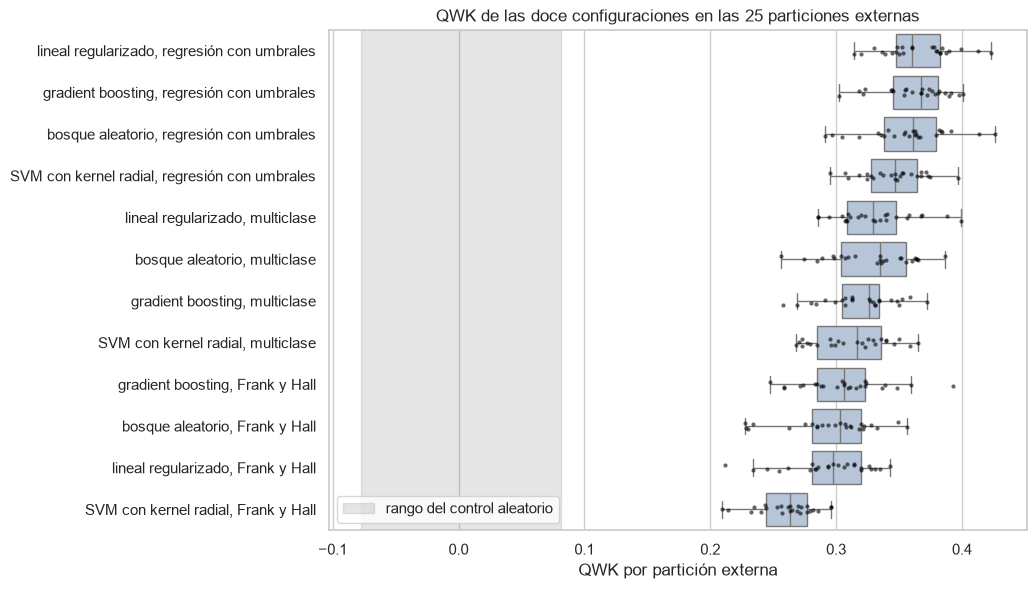

In [17]:
# QWK de cada partición externa por configuración, en el orden de la tabla anterior.
qwk_por_particion = pd.concat(
    [
        resultado.folds[["repeat", "fold", "qwk"]].assign(
            configuración=f"{NOMBRES_ALGORITMOS[a]}, {NOMBRES_FORMULACIONES[f]}"
        )
        for (a, f), resultado in resultados_e2.items()
    ],
    ignore_index=True,
)
orden = [f"{a}, {f}" for a, f in desempeno_e2.index]
qwk_aleatorio = resultados_controles["aleatorio estratificado"][0]["qwk"]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.axvspan(
    qwk_aleatorio.min(),
    qwk_aleatorio.max(),
    color="grey",
    alpha=0.2,
    label="rango del control aleatorio",
)
sns.boxplot(
    data=qwk_por_particion,
    x="qwk",
    y="configuración",
    order=orden,
    color="lightsteelblue",
    showfliers=False,
    ax=ax,
)
sns.stripplot(
    data=qwk_por_particion,
    x="qwk",
    y="configuración",
    order=orden,
    color="black",
    size=3,
    alpha=0.6,
    ax=ax,
)
ax.set(
    xlabel="QWK por partición externa",
    ylabel="",
    title="QWK de las doce configuraciones en las 25 particiones externas",
)
# La leyenda va sobre la franja del control, donde no hay cajas.
ax.legend(loc="lower left")
save_figure(fig, "qwk_por_configuracion", FIGURAS)
plt.show()

### Conclusión

- **Frente a los controles.** Las doce configuraciones aprenden de los predictores: el QWK más bajo de una partición en cualquier configuración (0,209) supera con amplitud el máximo del control aleatorio (0,082), cuyo QWK medio es prácticamente cero.
- **Formulación y algoritmo.** La formulación ordena el desempeño más que el algoritmo. Las cuatro regresiones con umbrales encabezan el QWK (0,345 a 0,365), seguidas de las configuraciones multiclase (0,312 a 0,331) y de Frank y Hall (0,260 a 0,307). Dentro de cada formulación, los algoritmos están a 0,02 o menos entre sí, salvo la SVM con Frank y Hall.
- **Variabilidad.** La desviación del QWK entre repeticiones es pequeña (0,015 como máximo), pero de una partición a otra el QWK de una misma configuración varía en unos 0,1. Las diferencias entre configuraciones son del orden de esa variación, así que compararlas exige la prueba pareada de la regla de selección, no solo las medias.
- **QWK frente a los niveles altos.** El QWK y la detección de los niveles altos van en direcciones opuestas. Las regresiones con umbrales tienen el mayor QWK, pero casi nunca asignan el nivel severo (recall severo de 0,041 como máximo) y subestiman cerca de dos tercios de los participantes moderados o severos. Las configuraciones de Frank y Hall asignan correctamente el nivel severo a entre el 37 % y el 87 % de esos participantes y tienen la menor tasa de subestimación (0,35 a 0,47), a costa de casi no asignar el nivel leve. Las multiclase quedan en un punto intermedio. Como el QWK pondera cada participante por igual y los severos son el 1,2 % de la muestra, acertar en los niveles frecuentes pesa mucho más en la métrica que detectar a los severos.
- **Convergencia.** En las 25 particiones, la proporción de ajustes sin convergencia del modelo lineal es la misma que en la primera repetición: 44,4 % en la formulación multiclase y 17,7 % en Frank y Hall. Las advertencias del imputador son escasas frente al número de ajustes. Esos ajustes se evalúan con la solución aproximada del optimizador, así que el QWK de esas dos configuraciones podría estar algo subestimado. Aun así, ambas quedan por debajo de las cuatro regresiones con umbrales.
- **Recorte.** Con el nivel de recorte 1, la SVM se ajustó solo con la ponderación completa ($\alpha = 1$), mientras que las demás configuraciones eligen $\alpha$ en la validación interna. Su comparación con las demás es, por eso, condicional a ese recorte.
- **Duración.** Con los tiempos guardados de cada partición y la misma fórmula de la proyección, la búsqueda completa cuesta unas 11,1 horas, frente a las 9,85 proyectadas en la sección 3. La diferencia viene sobre todo del primer grupo, cuyas particiones tardaron más que en la primera repetición. La regla de recorte se aplicó con la proyección, como estaba definida, y no se corrige con los tiempos posteriores. Las particiones de la primera repetición ya estaban ajustadas desde la sección 3, así que la ejecución de esta sección tomó menos que la estimación.

La sección 5 revisa los hiperparámetros elegidos en cada partición, incluidos los que caen en los bordes de las grillas, y la sección 6 aplica la regla de selección.

## 5. Hiperparámetros elegidos y revisión de los bordes

En cada partición externa, la validación interna elige la estrategia de faltantes, el exponente de la ponderación y los hiperparámetros del modelo. Esta sección resume esas elecciones y aplica la regla de bordes de la sección 2: un extremo de la grilla elegido en al menos 5 de las 25 particiones se amplía un paso.

La sección 2 fija el criterio de la regla. Aquí, al aplicarla, se definen los detalles que dependen de la forma de cada grilla: qué hiperparámetros tienen un borde que revisar y cuánto se amplía cada uno. Ninguno de esos detalles usa el QWK; solo intervienen los valores de la grilla y los hiperparámetros elegidos en la validación interna.

- *Hiperparámetros revisados:* los numéricos con al menos tres valores en su grilla. Con dos valores, como el exponente $\alpha$, la tasa de aprendizaje de gradient boosting o el `epsilon` de la SVR, cualquier elección es un extremo y no indica que el óptimo esté fuera de la grilla. La estrategia de faltantes es categórica.
- *Paso de la ampliación:* repite la razón entre los dos valores más cercanos al borde, porque las grillas son geométricas; por ejemplo, `C` pasa de 100 a 1.000. Los hiperparámetros enteros siguen siendo enteros.
- *Límites naturales:* un borde que coincide con el límite del hiperparámetro no se amplía. Es el caso de `l1_ratio` en 0 o 1 (ridge o lasso), `max_features` igual a 1 (todas las variables), `min_samples_leaf` igual a 1, `max_leaf_nodes` igual a 2 y `l2_regularization` igual a 0.
- *Grilla revisada:* la que usó cada configuración en la búsqueda completa, después del nivel de recorte.

Las configuraciones que la regla amplía se repiten una sola vez con la grilla ampliada, y sus resultados se guardan aparte de los de la búsqueda completa.

In [18]:
def etiqueta_configuracion(configuracion: tuple[str, str]) -> tuple[str, str]:
    """Nombres en español de una configuración, para los índices de las tablas."""
    algoritmo, formulacion = configuracion
    return NOMBRES_ALGORITMOS[algoritmo], NOMBRES_FORMULACIONES[formulacion]


# Hiperparámetros elegidos por la validación interna en cada partición externa.
elegidos = {c: list(r.folds["best_params"]) for c, r in resultados_e2.items()}

# Estrategia de faltantes y exponente de la ponderación: particiones, de las 25,
# en las que la validación interna eligió cada valor.
filas = []
for configuracion, parametros in elegidos.items():
    estrategias = chosen_value_counts(parametros, "preprocess__strategy")
    exponentes = chosen_value_counts(parametros, "model__weight_power")
    filas.append(
        {
            **{
                f"estrategia {NOMBRES_ESTRATEGIAS[e]}": int(estrategias.get(e, 0))
                for e in NOMBRES_ESTRATEGIAS
            },
            **{f"α = {a:g}": int(exponentes.get(a, 0)) for a in (0.5, 1.0)},
        }
    )
tratamiento_elegido = pd.DataFrame(
    filas,
    index=pd.MultiIndex.from_tuples(
        [etiqueta_configuracion(c) for c in elegidos],
        names=["algoritmo", "formulación"],
    ),
)
tratamiento_elegido

estrategia nativa  \
algoritmo             formulación                                 
lineal regularizado   multiclase                              0   
                      Frank y Hall                            0   
gradient boosting     regresión con umbrales                  4   
                      Frank y Hall                            8   
                      multiclase                              5   
SVM con kernel radial regresión con umbrales                  0   
                      Frank y Hall                            0   
                      multiclase                              0   
lineal regularizado   regresión con umbrales                  0   
bosque aleatorio      regresión con umbrales                  0   
                      Frank y Hall                            0   
                      multiclase                              0   

                                              estrategia simple con indicadores  \
algoritmo             formulación                                                 
lineal regularizado   multiclase                                             20   
                      Frank y Hall                                           18   
gradient boosting     regresión con umbrales                                 11   
                      Frank y Hall                                            8   
                      multiclase                                              5   
SVM con kernel radial regresión con umbrales                                  5   
                      Frank y Hall                                           16   
                      multiclase                                              8   
lineal regularizado   regresión con umbrales                                  5   
bosque aleatorio      regresión con umbrales                                  7   
                      Frank y Hall                                           12   
                      multiclase                                              7   

                                              estrategia iterativa  α = 0.5  \
algoritmo             formulación                                             
lineal regularizado   multiclase                                 5       25   
                      Frank y Hall                               7        6   
gradient boosting     regresión con umbrales                    10       23   
                      Frank y Hall                               9        4   
                      multiclase                                15       18   
SVM con kernel radial regresión con umbrales                    20        0   
                      Frank y Hall                               9        0   
                      multiclase                                17        0   
lineal regularizado   regresión con umbrales                    20       25   
bosque aleatorio      regresión con umbrales                    18       18   
                      Frank y Hall                              13        0   
                      multiclase                                18        7   

                                              α = 1  
algoritmo             formulación                    
lineal regularizado   multiclase                  0  
                      Frank y Hall               19  
gradient boosting     regresión con umbrales      2  
                      Frank y Hall               21  
                      multiclase                  7  
SVM con kernel radial regresión con umbrales     25  
                      Frank y Hall               25  
                      multiclase                 25  
lineal regularizado   regresión con umbrales      0  
bosque aleatorio      regresión con umbrales      7  
                      Frank y Hall               25  
                      multiclase                 18

In [19]:
# Regla de bordes sobre la grilla con la que se ejecutó cada configuración.
revisiones = []
for configuracion, parametros in elegidos.items():
    grilla = tareas_e2[configuracion].estimator.param_grid
    revision = edge_review(parametros, grilla)
    revisiones.append(
        revision.assign(
            algoritmo=NOMBRES_ALGORITMOS[configuracion[0]],
            formulación=NOMBRES_FORMULACIONES[configuracion[1]],
            hiperparámetro=revision["parameter"].map(parameter_short_name),
        )
    )
revision_bordes = (
    pd.concat(revisiones, ignore_index=True)
    .rename(
        columns={
            "edge": "borde",
            "edge_value": "valor del borde",
            "folds_at_edge": "particiones en el borde",
            "extension_value": "valor de la ampliación",
            "extend": "se amplía",
        }
    )
    .replace({"borde": {"lower": "inferior", "upper": "superior"}})
    .set_index(["algoritmo", "formulación", "hiperparámetro", "borde"])
)[["valor del borde", "particiones en el borde", "valor de la ampliación", "se amplía"]]

# Ampliaciones que exige la regla, por configuración.
AMPLIACIONES = {
    configuracion: grid_extension(revision)
    for configuracion, revision in zip(elegidos, revisiones, strict=True)
    if grid_extension(revision)
}
print(
    f"Bordes revisados: {len(revision_bordes)}; elegidos en al menos "
    f"{EDGE_RULE_MIN_FOLDS} particiones: "
    f"{int((revision_bordes['particiones en el borde'] >= EDGE_RULE_MIN_FOLDS).sum())}; "
    f"se amplían: {int(revision_bordes['se amplía'].sum())}"
)
for configuracion, ampliacion in AMPLIACIONES.items():
    valores = "; ".join(
        f"{parameter_short_name(p)}: {', '.join(f'{v:g}' for v in vs)}"
        for p, vs in ampliacion.items()
    )
    print(f"Se amplía {', '.join(etiqueta_configuracion(configuracion))}: {valores}")
# Solo se muestran los bordes elegidos en al menos una partición.
revision_bordes[revision_bordes["particiones en el borde"] > 0]

Bordes revisados: 48; elegidos en al menos 5 particiones: 25; se amplían: 16
Se amplía lineal regularizado, Frank y Hall: C: 1000
Se amplía gradient boosting, regresión con umbrales: max_leaf_nodes: 3; min_samples_leaf: 3, 213; l2_regularization: 100
Se amplía gradient boosting, Frank y Hall: max_leaf_nodes: 3; min_samples_leaf: 3; l2_regularization: 100
Se amplía gradient boosting, multiclase: max_leaf_nodes: 3; min_samples_leaf: 3, 213; l2_regularization: 100
Se amplía SVM con kernel radial, regresión con umbrales: gamma: 1e-05
Se amplía SVM con kernel radial, Frank y Hall: gamma: 1e-05
Se amplía bosque aleatorio, regresión con umbrales: min_samples_leaf: 125
Se amplía bosque aleatorio, multiclase: min_samples_leaf: 125


valor del borde  \
algoritmo             formulación            hiperparámetro    borde                      
lineal regularizado   multiclase             C                 superior           100.0   
                                             l1_ratio          inferior             0.0   
                                                               superior             1.0   
                      Frank y Hall           C                 superior           100.0   
                                             l1_ratio          inferior             0.0   
                                                               superior             1.0   
gradient boosting     regresión con umbrales max_leaf_nodes    inferior               7   
                                             min_samples_leaf  inferior              10   
                                                               superior              80   
                                             l2_regularization inferior             0.0   
                                                               superior            10.0   
                      Frank y Hall           max_leaf_nodes    inferior               7   
                                                               superior              31   
                                             min_samples_leaf  inferior              10   
                                                               superior              80   
                                             l2_regularization inferior             0.0   
                                                               superior            10.0   
                      multiclase             max_leaf_nodes    inferior               7   
                                                               superior              31   
                                             min_samples_leaf  inferior              10   
                                                               superior              80   
                                             l2_regularization inferior             0.0   
                                                               superior            10.0   
SVM con kernel radial regresión con umbrales C                 superior          1000.0   
                                             gamma             inferior          0.0001   
                      Frank y Hall           C                 superior          1000.0   
                                             gamma             inferior          0.0001   
lineal regularizado   regresión con umbrales l1_ratio          inferior             0.0   
                                                               superior             1.0   
bosque aleatorio      regresión con umbrales min_samples_leaf  superior              50   
                      multiclase             min_samples_leaf  inferior               1   
                                                               superior              50   

                                                                         particiones en el borde  \
algoritmo             formulación            hiperparámetro    borde                               
lineal regularizado   multiclase             C                 superior                        2   
                                             l1_ratio          inferior                       10   
                                                               superior                        7   
                      Frank y Hall           C                 superior                        8   
                                             l1_ratio          inferior                        5   
                                                               superior                       15   
gradient boosting     regresión con umbrales max_leaf_nodes    inferior                       22   
                                             min_samples_leaf  inferior      

### Búsquedas con las grillas ampliadas

Cada configuración con algún borde ampliado se repite una sola vez, con su grilla ampliada y con el mismo nivel de recorte, límite de iteraciones y particiones de la búsqueda completa, de modo que sus resultados son comparables partición por partición.

La repetición no vuelve a evaluar los candidatos de la grilla original. Cada candidato se evalúa en las mismas tres particiones internas y con las mismas semillas, así que su QWK interno no depende de los demás candidatos de la grilla. Por eso, en cada partición externa solo los candidatos nuevos pasan por la validación interna, sus resultados se suman a los ya guardados y se elige el candidato que elegiría la búsqueda completa con la grilla ampliada, incluido el desempate. El modelo se reajusta solo si ese candidato cambia; si no, la predicción de la partición es la misma de la búsqueda completa. El resultado es idéntico al de repetir la búsqueda entera, con el costo de los candidatos nuevos.

Antes de ejecutarlas se proyecta su costo con los tiempos de la búsqueda completa, escalados por la proporción de candidatos nuevos.

In [20]:
def numero_candidatos(grilla: dict) -> int:
    """Número de candidatos de una grilla completa."""
    return int(np.prod([len(valores) for valores in grilla.values()]))


# Búsquedas con la grilla ampliada: misma configuración, nivel de recorte, límite
# de iteraciones y particiones que en la búsqueda completa. Con los resultados de
# la búsqueda completa (previous), cada partición evalúa solo los candidatos
# nuevos y los combina con los resultados internos ya guardados.
tareas_bordes = {
    configuracion: make_search_task(
        *configuracion,
        "main",
        X_principal,
        y,
        particiones,
        cut_level=NIVEL_RECORTE,
        max_iter_factor=FACTOR_ITERACIONES[configuracion],
        memory=str(CARPETA_MEMORIA),
        grid_extension=ampliacion,
        name_suffix="__extended",
        previous=resultados_e2[configuracion],
    )
    for configuracion, ampliacion in AMPLIACIONES.items()
}

# Proyección del tiempo: minutos por partición medidos en la búsqueda completa,
# escalados por la proporción de candidatos nuevos, con los procesos de cada grupo.
costo_bordes = pd.DataFrame(
    [
        {
            "algoritmo": NOMBRES_ALGORITMOS[c[0]],
            "formulación": NOMBRES_FORMULACIONES[c[1]],
            "candidatos": numero_candidatos(tareas_e2[c].estimator.param_grid),
            "candidatos con la ampliación": numero_candidatos(
                tarea.estimator.param_grid
            ),
            "minutos por partición (búsqueda completa)": (
                resultados_e2[c].folds["fit_seconds"].mean() / 60
            ),
        }
        for c, tarea in tareas_bordes.items()
    ],
    index=list(tareas_bordes),
)
costo_bordes["candidatos nuevos"] = (
    costo_bordes["candidatos con la ampliación"] - costo_bordes["candidatos"]
)
costo_bordes["minutos por partición proyectados"] = (
    costo_bordes["minutos por partición (búsqueda completa)"]
    * costo_bordes["candidatos nuevos"]
    / costo_bordes["candidatos"]
)
horas_proyectadas_bordes = 0.0
for grupo in EXECUTION_POOLS:
    minutos = costo_bordes.loc[
        [c for c in tareas_bordes if c[0] in grupo], "minutos por partición proyectados"
    ]
    if len(minutos):
        horas_proyectadas_bordes += (
            len(particiones) * minutos.sum() / procesos_e2[grupo] + minutos.max()
        ) / 60
print(f"Horas proyectadas para las búsquedas ampliadas: {horas_proyectadas_bordes:.1f}")
costo_bordes.set_index(["algoritmo", "formulación"]).round(1)

Horas proyectadas para las búsquedas ampliadas: 5.2


candidatos  \
algoritmo             formulación                          
lineal regularizado   Frank y Hall                    84   
gradient boosting     regresión con umbrales         324   
                      Frank y Hall                   324   
                      multiclase                     324   
SVM con kernel radial regresión con umbrales         120   
                      Frank y Hall                    60   
bosque aleatorio      regresión con umbrales          64   
                      multiclase                      64   

                                              candidatos con la ampliación  \
algoritmo             formulación                                            
lineal regularizado   Frank y Hall                                      96   
gradient boosting     regresión con umbrales                           960   
                      Frank y Hall                                     768   
                      multiclase                                       960   
SVM con kernel radial regresión con umbrales                           144   
                      Frank y Hall                                      72   
bosque aleatorio      regresión con umbrales                            80   
                      multiclase                                        80   

                                              minutos por partición (búsqueda completa)  \
algoritmo             formulación                                                         
lineal regularizado   Frank y Hall                                                 47.5   
gradient boosting     regresión con umbrales                                       28.8   
                      Frank y Hall                                                 24.2   
                      multiclase                                                   10.2   
SVM con kernel radial regresión con umbrales                                        2.9   
                      Frank y Hall                                                  2.3   
bosque aleatorio      regresión con umbrales                                       11.6   
                      multiclase                                                    5.2   

                                              candidatos nuevos  \
algoritmo             formulación                                 
lineal regularizado   Frank y Hall                           12   
gradient boosting     regresión con umbrales                636   
                      Frank y Hall                          444   
                      multiclase                            636   
SVM con kernel radial regresión con umbrales                 24   
                      Frank y Hall                           12   
bosque aleatorio      regresión con umbrales                 16   
                      multiclase                             16   

                                              minutos por partición proyectados  
algoritmo             formulación                                                
lineal regularizado   Frank y Hall                                          6.8  
gradient boosting     regresión con umbrales                               56.6  
                      Frank y Hall                                         33.2  
                      multiclase                                           20.1  
SVM con kernel radial regresión con umbrales                                0.6  
                      Frank y Hall                                          0.5  
bosque aleatorio      regresión con umbrales                                2.9  
                      multiclase                                            1.3

In [21]:
resultados_bordes = {}
horas_bordes = {}
errores_bordes = {}
for grupo in EXECUTION_POOLS:
    # Las configuraciones más costosas se envían primero.
    configuraciones_grupo = sorted(
        (c for c in tareas_bordes if c[0] in grupo),
        key=lambda c: costo_bordes.loc[[c], "minutos por partición proyectados"].iloc[
            0
        ],
        reverse=True,
    )
    if not configuraciones_grupo:
        continue
    inicio = time.perf_counter()
    try:
        resultados_grupo = run_configurations_cached(
            [tareas_bordes[c] for c in configuraciones_grupo],
            cache_dir=CARPETA_CACHE,
            n_jobs=procesos_e2[grupo],
            force=RECALCULAR,
            verbose=5,
        )
    except RuntimeError as error:
        # Las particiones que sí terminaron ya están guardadas. El otro grupo se
        # ejecuta igual y el error se muestra al final.
        errores_bordes[grupo] = error
        continue
    horas_bordes[grupo] = (time.perf_counter() - inicio) / 3_600
    for configuracion in configuraciones_grupo:
        resultados_bordes[configuracion] = resultados_grupo[
            tareas_bordes[configuracion].name
        ]

if errores_bordes:
    raise RuntimeError(
        "Algunas particiones no terminaron; al volver a ejecutar la celda solo se "
        f"ajustan las que faltan: {errores_bordes}"
    )

for grupo, horas in horas_bordes.items():
    print(f"Grupo {nombres_grupos[grupo]}: {horas:.2f} horas en esta ejecución")
pd.DataFrame(
    [
        {
            "algoritmo": NOMBRES_ALGORITMOS[a],
            "formulación": NOMBRES_FORMULACIONES[f],
            "cargadas": resultado.counts()["loaded"],
            "calculadas": resultado.counts()["computed"],
            "minutos por partición (media)": resultado.folds["fit_seconds"].mean() / 60,
            "candidatos nuevos por partición": int(
                resultado.folds["new_candidates"].iloc[0]
            ),
            "particiones con otro candidato elegido": int(
                resultado.folds["best_changed"].sum()
            ),
        }
        for (a, f), resultado in resultados_bordes.items()
    ]
).set_index(["algoritmo", "formulación"]).round(2)

Grupo lineal regularizado, SVM con kernel radial, gradient boosting: 0.00 horas en esta ejecución
Grupo bosque aleatorio: 0.00 horas en esta ejecución


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.
[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.


cargadas  calculadas  \
algoritmo             formulación                                    
gradient boosting     regresión con umbrales        25           0   
                      Frank y Hall                  25           0   
                      multiclase                    25           0   
lineal regularizado   Frank y Hall                  25           0   
SVM con kernel radial regresión con umbrales        25           0   
                      Frank y Hall                  25           0   
bosque aleatorio      regresión con umbrales        25           0   
                      multiclase                    25           0   

                                              minutos por partición (media)  \
algoritmo             formulación                                             
gradient boosting     regresión con umbrales                          52.44   
                      Frank y Hall                                    31.45   
                      multiclase                                      20.14   
lineal regularizado   Frank y Hall                                    11.09   
SVM con kernel radial regresión con umbrales                           0.42   
                      Frank y Hall                                     0.42   
bosque aleatorio      regresión con umbrales                           1.28   
                      multiclase                                       0.57   

                                              candidatos nuevos por partición  \
algoritmo             formulación                                               
gradient boosting     regresión con umbrales                              636   
                      Frank y Hall                                        444   
                      multiclase                                          636   
lineal regularizado   Frank y Hall                                         12   
SVM con kernel radial regresión con umbrales                               24   
                      Frank y Hall                                         12   
bosque aleatorio      regresión con umbrales                               16   
                      multiclase                                           16   

                                              particiones con otro candidato elegido  
algoritmo             formulación                                                     
gradient boosting     regresión con umbrales                                      22  
                      Frank y Hall                                                 8  
                      multiclase                                                  21  
lineal regularizado   Frank y Hall                                                 5  
SVM con kernel radial regresión con umbrales                                       2  
                      Frank y Hall                                                 2  
bosque aleatorio      regresión con umbrales                                       5  
                      multiclase                                                   7

### Resultados con las grillas ampliadas

Las tablas siguientes comparan cada configuración ampliada con su versión de la búsqueda completa, sobre las mismas 25 particiones, y revisan los bordes de las grillas ampliadas. La regla amplía una sola vez, así que un borde que siga elegido con frecuencia solo se reporta. Desde aquí, los resultados de cada configuración ampliada son los de su grilla ampliada.

In [22]:
# Desempeño con la grilla original y con la ampliada, sobre las mismas particiones.
filas = []
for configuracion, ampliado in resultados_bordes.items():
    original = resultados_e2[configuracion]
    resumen_original = resumen_desempeno(original.folds, original.predictions)
    resumen_ampliado = resumen_desempeno(ampliado.folds, ampliado.predictions)
    diferencias = ampliado.folds["qwk"].to_numpy() - original.folds["qwk"].to_numpy()
    filas.append(
        {
            "algoritmo": NOMBRES_ALGORITMOS[configuracion[0]],
            "formulación": NOMBRES_FORMULACIONES[configuracion[1]],
            "QWK, grilla original": resumen_original["QWK"],
            "QWK, grilla ampliada": resumen_ampliado["QWK"],
            "diferencia de QWK": resumen_ampliado["QWK"] - resumen_original["QWK"],
            "particiones con mayor QWK": int((diferencias > 0).sum()),
            "particiones con menor QWK": int((diferencias < 0).sum()),
            "recall severo, grilla original": resumen_original["recall severo"],
            "recall severo, grilla ampliada": resumen_ampliado["recall severo"],
            "subestimación, grilla original": resumen_original[
                "subestimación moderado o severo"
            ],
            "subestimación, grilla ampliada": resumen_ampliado[
                "subestimación moderado o severo"
            ],
        }
    )
comparacion_grillas = pd.DataFrame(filas).set_index(["algoritmo", "formulación"])
comparacion_grillas.round(3)

QWK, grilla original  \
algoritmo             formulación                                    
gradient boosting     regresión con umbrales                 0.362   
                      Frank y Hall                           0.307   
                      multiclase                             0.319   
lineal regularizado   Frank y Hall                           0.294   
SVM con kernel radial regresión con umbrales                 0.345   
                      Frank y Hall                           0.260   
bosque aleatorio      regresión con umbrales                 0.357   
                      multiclase                             0.328   

                                              QWK, grilla ampliada  \
algoritmo             formulación                                    
gradient boosting     regresión con umbrales                 0.367   
                      Frank y Hall                           0.312   
                      multiclase                             0.330   
lineal regularizado   Frank y Hall                           0.296   
SVM con kernel radial regresión con umbrales                 0.346   
                      Frank y Hall                           0.261   
bosque aleatorio      regresión con umbrales                 0.356   
                      multiclase                             0.326   

                                              diferencia de QWK  \
algoritmo             formulación                                 
gradient boosting     regresión con umbrales              0.005   
                      Frank y Hall                        0.005   
                      multiclase                          0.011   
lineal regularizado   Frank y Hall                        0.002   
SVM con kernel radial regresión con umbrales              0.001   
                      Frank y Hall                        0.001   
bosque aleatorio      regresión con umbrales             -0.000   
                      multiclase                         -0.002   

                                              particiones con mayor QWK  \
algoritmo             formulación                                         
gradient boosting     regresión con umbrales                         13   
                      Frank y Hall                                    7   
                      multiclase                                     10   
lineal regularizado   Frank y Hall                                    2   
SVM con kernel radial regresión con umbrales                          1   
                      Frank y Hall                                    2   
bosque aleatorio      regresión con umbrales                          2   
                      multiclase                                      2   

                                              particiones con menor QWK  \
algoritmo             formulación                                         
gradient boosting     regresión con umbrales                          9   
                      Frank y Hall                                    1   
                      multiclase                                     11   
lineal regularizado   Frank y Hall                                    3   
SVM con kernel radial regresión con umbrales                          0   
                      Frank y Hall                                    0   
bosque aleatorio      regresión con umbrales                          3   
                      multiclase                                      5   

                                              recall severo, grilla original  \
algoritmo             formulación                                              
gradient boosting     regresión con umbrales                           0.041   
                      Frank y Hall                                     0.371   
                      multiclase                                       0.182   
lineal regularizado   Frank y Hall                                     

In [23]:
# Bordes de las grillas ampliadas. La regla amplía una sola vez, así que solo se
# reportan los que seguirían cumpliendo la condición de ampliación.
revisiones_ampliadas = []
for configuracion, ampliado in resultados_bordes.items():
    revision = edge_review(
        list(ampliado.folds["best_params"]),
        tareas_bordes[configuracion].estimator.param_grid,
    )
    revisiones_ampliadas.append(
        revision.assign(
            algoritmo=NOMBRES_ALGORITMOS[configuracion[0]],
            formulación=NOMBRES_FORMULACIONES[configuracion[1]],
            hiperparámetro=revision["parameter"].map(parameter_short_name),
        )
    )
bordes_ampliados = (
    pd.concat(revisiones_ampliadas, ignore_index=True)
    .rename(
        columns={
            "edge": "borde",
            "edge_value": "valor del borde",
            "folds_at_edge": "particiones en el borde",
        }
    )
    .replace({"borde": {"lower": "inferior", "upper": "superior"}})
    .set_index(["algoritmo", "formulación", "hiperparámetro", "borde"])
)
persistentes = bordes_ampliados[bordes_ampliados["extend"].astype(bool)]
print(
    f"Bordes de las grillas ampliadas elegidos en al menos {EDGE_RULE_MIN_FOLDS} "
    f"particiones y que admitirían otro paso: {len(persistentes)}"
)
persistentes[["valor del borde", "particiones en el borde"]]

Bordes de las grillas ampliadas elegidos en al menos 5 particiones y que admitirían otro paso: 12


valor del borde  \
algoritmo             formulación            hiperparámetro    borde                      
gradient boosting     regresión con umbrales max_leaf_nodes    inferior               3   
                                             min_samples_leaf  inferior               3   
                                                               superior             213   
                                             l2_regularization superior           100.0   
                      Frank y Hall           min_samples_leaf  inferior               3   
                      multiclase             max_leaf_nodes    inferior               3   
                                             min_samples_leaf  superior             213   
                                             l2_regularization superior           100.0   
lineal regularizado   Frank y Hall           C                 superior          1000.0   
SVM con kernel radial Frank y Hall           C                 superior          1000.0   
bosque aleatorio      regresión con umbrales min_samples_leaf  superior             125   
                      multiclase             min_samples_leaf  superior             125   

                                                                         particiones en el borde  
algoritmo             formulación            hiperparámetro    borde                              
gradient boosting     regresión con umbrales max_leaf_nodes    inferior                       13  
                                             min_samples_leaf  inferior                        5  
                                                               superior                        9  
                                             l2_regularization superior                       13  
                      Frank y Hall           min_samples_leaf  inferior                        8  
                      multiclase             max_leaf_nodes    inferior                       17  
                                             min_samples_leaf  superior                        7  
                                             l2_regularization superior                       13  
lineal regularizado   Frank y Hall           C                 superior                        5  
SVM con kernel radial Frank y Hall           C                 superior                        5  
bosque aleatorio      regresión con umbrales min_samples_leaf  superior                        5  
                      multiclase             min_samples_leaf  superior                        7

In [24]:
# Resultados que entran a la selección: la grilla ampliada cuando la regla de
# bordes amplió la configuración y la grilla de la búsqueda completa en otro caso.
resultados_finales = {**resultados_e2, **resultados_bordes}
tareas_finales = {**tareas_e2, **tareas_bordes}
pd.Series(
    {
        etiqueta_configuracion(c): "ampliada" if c in resultados_bordes else "original"
        for c in CONFIGURACIONES
    },
    name="grilla",
).rename_axis(["algoritmo", "formulación"]).to_frame()

grilla
algoritmo             formulación                     
lineal regularizado   regresión con umbrales  original
                      multiclase              original
                      Frank y Hall            ampliada
SVM con kernel radial regresión con umbrales  ampliada
                      multiclase              original
                      Frank y Hall            ampliada
bosque aleatorio      regresión con umbrales  ampliada
                      multiclase              ampliada
                      Frank y Hall            original
gradient boosting     regresión con umbrales  ampliada
                      multiclase              ampliada
                      Frank y Hall            ampliada

### Conclusión

- **Tratamiento elegido.** La ponderación depende sobre todo de la formulación. En la regresión con umbrales, el modelo lineal, gradient boosting y el bosque aleatorio eligen $\alpha = 0{,}5$ en 25, 23 y 18 de las 25 particiones, mientras que en Frank y Hall predomina $\alpha = 1$ (de 19 a 25 particiones). La SVM usa siempre $\alpha = 1$ porque el nivel de recorte dejó solo ese valor en su grilla. La imputación iterativa se elige en la mayoría de las particiones de la SVM y del bosque con regresión y multiclase, y del lineal con regresión (de 17 a 20); la simple con indicadores, en el lineal multiclase y de Frank y Hall y en la SVM con Frank y Hall (de 16 a 20). La estrategia nativa de gradient boosting solo se elige en 4 a 8 particiones.
- **Bordes.** De los 48 bordes revisados, 25 se eligieron en al menos 5 particiones. De ellos, 16 admitían una ampliación, repartida en ocho configuraciones; los demás estaban en límites naturales, sobre todo `l1_ratio` en 0 o 1. Salvo el lineal con Frank y Hall, que amplió `C` hacia menos regularización, las ampliaciones apuntan a modelos más regularizados: árboles de gradient boosting con menos hojas y más regularización L2, hojas más grandes en el bosque y un `gamma` menor en la SVM.
- **Efecto de la ampliación.** La grilla ampliada cambió el candidato elegido en buena parte de las particiones de gradient boosting y en pocas del resto, pero el QWK medio cambió entre −0,002 y +0,011. Gradient boosting fue el que más ganó (0,005 en regresión con umbrales y Frank y Hall, 0,011 en multiclase). El recall severo y la tasa de subestimación cambiaron en la misma escala, aunque en gradient boosting multiclase el recall severo bajó de 0,182 a 0,118.
- **Bordes persistentes.** En las grillas ampliadas, 12 bordes siguen eligiéndose en al menos 5 particiones, sobre todo en gradient boosting (`max_leaf_nodes = 3` en 13 y 17 particiones, `l2_regularization = 100` en 13). Como la regla amplía una sola vez, quedan como una limitación: el óptimo de esas configuraciones podría estar en modelos aún más regularizados. Dado que la primera ampliación cambió el QWK en una centésima o menos, no se espera que un segundo paso altere la comparación entre configuraciones.

Los resultados que entran a la selección son los de la grilla ampliada en las ocho configuraciones ampliadas y los de la búsqueda completa en las otras cuatro.

## 6. Selección de la configuración

La regla de la sección 2 se aplica a los resultados de las doce configuraciones en las 25 particiones externas:

1. Se identifica la configuración de mayor QWK medio y se compara con cada una de las demás mediante la prueba t corregida de Nadeau y Bengio sobre las diferencias de QWK por partición, unilateral, con $\alpha = 0{,}05$ y sin ajuste por multiplicidad. La mejor y las que no difieren significativamente de ella son las candidatas.
2. Entre las candidatas se elige la de menor tasa de subestimación de los niveles moderado y severo. Dos tasas que difieren en menos de 0,01 se consideran empatadas.
3. Un empate se resuelve a favor de la configuración más simple: primero el algoritmo, luego la formulación y luego la estrategia de faltantes elegida en más particiones.

La validación anidada estima el desempeño de cada configuración con particiones de evaluación que no intervienen en su ajuste. El sesgo optimista viene de elegir entre doce configuraciones con esas mismas particiones: el QWK de la elegida tiende a ser mayor que el que tendría con datos nuevos, y el sesgo es mayor cuanto más se aleja la elegida de las demás.

Después de aplicar la regla, una figura sitúa las doce configuraciones según su QWK y según dos medidas de los niveles altos: la tasa de subestimación de los niveles moderado y severo y el recall severo. Así se ve qué implica cada elección en esos niveles.

In [25]:
# Paso 1: comparación de cada configuración con la de mayor QWK medio, con la prueba
# t corregida de Nadeau y Bengio sobre las diferencias por partición.
comparacion = compare_with_best(
    {c: resultado.folds for c, resultado in resultados_finales.items()},
    alpha=SELECTION_ALPHA,
)

# Paso 2: tasa de subestimación de los niveles moderado y severo, promediada entre
# repeticiones.
subestimacion = {
    c: resumen_desempeno(r.folds, r.predictions)["subestimación moderado o severo"]
    for c, r in resultados_finales.items()
}

# Paso 3: complejidad, con la estrategia de faltantes elegida en más particiones.
estrategia_frecuente = {
    c: most_frequent_value(list(r.folds["best_params"]), "preprocess__strategy")
    for c, r in resultados_finales.items()
}
complejidad = {c: complexity_key(*c, estrategia_frecuente[c]) for c in CONFIGURACIONES}

regla = apply_selection_rule(comparacion, subestimacion, complejidad)
SELECCIONADA = selected_configuration(regla)

tabla_seleccion = pd.DataFrame(
    {
        "QWK": regla["mean_qwk"],
        "diferencia con la mejor": regla["mean_difference"],
        "t corregido": regla["corrected_t"],
        "valor p (unilateral)": regla["p_value_one_sided"],
        "candidata (paso 1)": regla["candidate"],
        "subestimación moderado o severo": regla["underestimation"],
        "empate en subestimación (paso 2)": regla["tied_underestimation"],
        "estrategia más frecuente": pd.Series(
            {c: NOMBRES_ESTRATEGIAS[e] for c, e in estrategia_frecuente.items()}
        ),
        "seleccionada": regla["selected"],
    }
)
tabla_seleccion.index = pd.MultiIndex.from_tuples(
    [etiqueta_configuracion(c) for c in tabla_seleccion.index],
    names=["algoritmo", "formulación"],
)
tabla_seleccion = tabla_seleccion.sort_values("QWK", ascending=False)
print(
    "Configuración seleccionada: "
    + ", ".join(etiqueta_configuracion(SELECCIONADA))
    + f" (grilla {'ampliada' if SELECCIONADA in resultados_bordes else 'original'})"
)
tabla_seleccion.round(3)

Configuración seleccionada: lineal regularizado, regresión con umbrales (grilla original)


,,QWK,diferencia con la mejor,t corregido,valor p (unilateral),candidata (paso 1),subestimación moderado o severo,empate en subestimación (paso 2),estrategia más frecuente,seleccionada
algoritmo,formulación,,,,,,,,,
gradient boosting,regresión con umbrales,0.367,0.000,NaN,NaN,True,0.690,False,iterativa,False
lineal regularizado,regresión con umbrales,0.365,0.002,0.174,0.432,True,0.683,True,iterativa,True
bosque aleatorio,regresión con umbrales,0.356,0.011,0.714,0.241,True,0.706,False,iterativa,False
SVM con kernel radial,regresión con umbrales,0.346,0.022,1.578,0.064,True,0.676,True,iterativa,False
lineal regularizado,multiclase,0.331,0.036,2.190,0.019,False,0.707,False,simple con indicadores,False
gradient boosting,multiclase,0.330,0.038,2.200,0.019,False,0.721,False,iterativa,False
bosque aleatorio,multiclase,0.326,0.041,2.032,0.027,False,0.691,False,iterativa,False
SVM con kernel radial,multiclase,0.312,0.055,2.816,0.005,False,0.597,False,iterativa,False
gradient boosting,Frank y Hall,0.312,0.056,3.997,0.000,False,0.466,False,iterativa,False


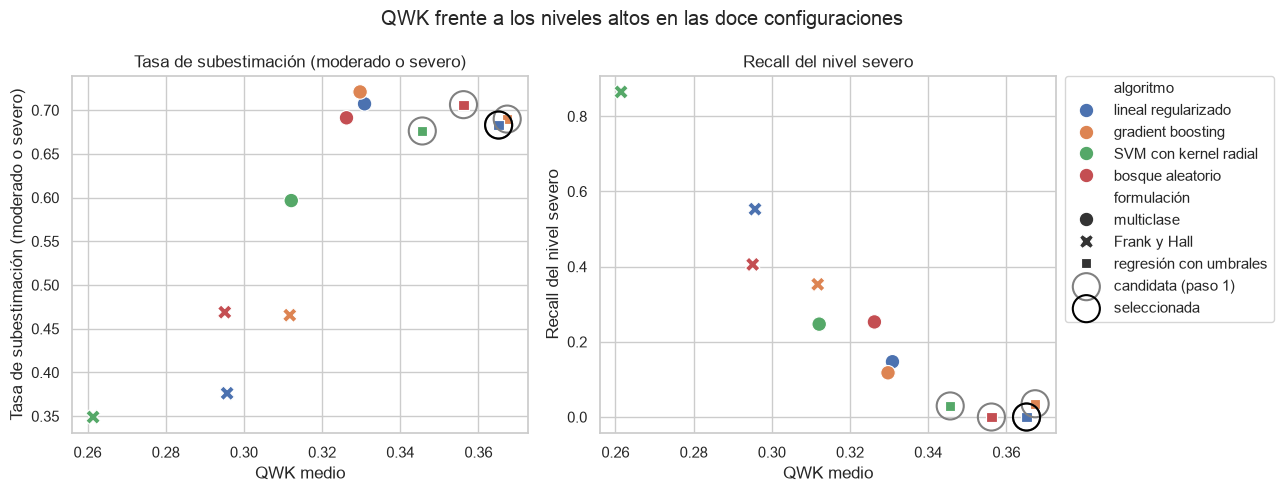

In [26]:
# QWK medio frente a la tasa de subestimación de los niveles moderado y severo y
# frente al recall severo, en las doce configuraciones que entran a la selección.
candidatas = {c for c in resultados_finales if bool(regla.loc[[c], "candidate"].iloc[0])}
dispersion = pd.DataFrame(
    [
        {
            "algoritmo": NOMBRES_ALGORITMOS[a],
            "formulación": NOMBRES_FORMULACIONES[f],
            "candidata": (a, f) in candidatas,
            "seleccionada": (a, f) == SELECCIONADA,
            **resumen_desempeno(r.folds, r.predictions),
        }
        for (a, f), r in resultados_finales.items()
    ]
)

PANELES = {
    "subestimación moderado o severo": "Tasa de subestimación (moderado o severo)",
    "recall severo": "Recall del nivel severo",
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, (columna, titulo) in zip(axes, PANELES.items(), strict=True):
    sns.scatterplot(
        data=dispersion,
        x="QWK",
        y=columna,
        hue="algoritmo",
        style="formulación",
        s=110,
        ax=ax,
    )
    # Las candidatas del paso 1 llevan un anillo gris y la seleccionada, uno negro.
    for filtro, color, etiqueta in (
        (dispersion["candidata"], "grey", "candidata (paso 1)"),
        (dispersion["seleccionada"], "black", "seleccionada"),
    ):
        ax.scatter(
            dispersion.loc[filtro, "QWK"],
            dispersion.loc[filtro, columna],
            s=380,
            facecolors="none",
            edgecolors=color,
            linewidths=1.5,
            label=etiqueta,
        )
    ax.set(xlabel="QWK medio", ylabel=titulo, title=titulo)
axes[0].get_legend().remove()
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
fig.suptitle("QWK frente a los niveles altos en las doce configuraciones")
fig.tight_layout()
save_figure(fig, "qwk_frente_a_niveles_altos", FIGURAS)
plt.show()

### Conclusión

- **Paso 1.** La configuración de mayor QWK medio es gradient boosting con regresión con umbrales y grilla ampliada (0,367). Las otras tres regresiones con umbrales no difieren significativamente de ella: el modelo lineal (diferencia de 0,002, $p = 0{,}43$), el bosque aleatorio (0,011, $p = 0{,}24$) y la SVM (0,022, $p = 0{,}064$). Todas las configuraciones multiclase y de Frank y Hall tienen un QWK significativamente menor ($p \le 0{,}027$). Las cuatro candidatas comparten formulación, lo que confirma que la formulación pesa más que el algoritmo.
- **Paso 2.** Entre las candidatas, la SVM tiene la menor tasa de subestimación (0,676), y la del modelo lineal (0,683) está a menos de 0,01, así que ambas quedan empatadas. Gradient boosting (0,690) y el bosque aleatorio (0,706) quedan fuera del empate.
- **Paso 3.** El empate se resuelve por complejidad a favor del modelo lineal.
- **La SVM y el recorte.** La SVM quedó candidata y empatada aun ajustándose solo con $\alpha = 1$, mientras que las otras tres regresiones con umbrales eligieron $\alpha = 0{,}5$ en la mayoría de las particiones (de 18 a 25, sección 5). La descartó el criterio de complejidad, no su desempeño, así que el recorte no eliminó una alternativa con mejor QWK. Su posición frente a las demás sigue siendo condicional a ese recorte.
- **Sesgo optimista.** Las cuatro candidatas están a 0,022 o menos de la mejor, y la seleccionada no es la de mayor QWK: está 0,002 por debajo. Ninguna candidata se separa de las demás, así que el sesgo por elegir entre ellas es pequeño frente a la variación del QWK entre particiones, de unos 0,1.
- **QWK frente a los niveles altos.** La figura separa las tres formulaciones. Las regresiones con umbrales tienen el mayor QWK, pero subestiman a cerca del 70 % de los participantes moderados o severos y casi no asignan el nivel severo (recall de 0,035 como máximo). Las de Frank y Hall tienen el menor QWK (0,261 a 0,312), pero la menor tasa de subestimación (0,349 a 0,469) y un recall severo de 0,35 a 0,87. Las multiclase quedan en un punto intermedio, con un recall severo de 0,12 a 0,25. La regla de selección prioriza el QWK y solo usa la subestimación para desempatar entre configuraciones equivalentes en QWK, así que elige dentro del grupo que menos asigna los niveles altos.

La configuración seleccionada es el **modelo lineal regularizado (elastic net) con regresión con umbrales**, con la grilla de la búsqueda completa. En la mayoría de las particiones, su validación interna eligió la imputación iterativa y la ponderación $\alpha = 0{,}5$. Su QWK medio (0,365) tiene el sesgo optimista descrito. No asigna el nivel severo a ningún participante en ninguna repetición; la sección 7 analiza su desempeño por nivel y a qué niveles van los participantes severos.

## 7. Desempeño de la configuración seleccionada por nivel

La configuración seleccionada se describe con las predicciones que produjo en las 25 particiones externas. Esta sección no entrena modelos nuevos.

- **Por repetición.** Dentro de una repetición, cada participante se predice exactamente una vez. Por eso, el recall de cada nivel y la tasa de subestimación de los niveles moderado y severo se calculan sobre las predicciones de la repetición, y el QWK es la media de sus cinco particiones. Se reporta cada repetición junto con la media y la desviación estándar entre las cinco.
- **Nivel severo.** Con solo 34 participantes severos, el recall de este nivel es muy incierto. Se reporta por repetición, con su intervalo de Wilson del 95 %. Si la desviación estándar entre repeticiones supera 0,10 (unos tres casos), el resultado se considera inestable y la evaluación de esta configuración se extiende a 10 repeticiones. Las repeticiones reutilizan a los mismos participantes, así que el intervalo del recall sobre todas ellas se obtiene remuestreando participantes: 10.000 remuestreos, con intervalo de percentiles. También se reporta a qué niveles se asignan los participantes severos.
- **Comparación pareada.** El recall severo de la configuración seleccionada se compara con el de la configuración de mayor QWK medio de cada uno de los otros tres algoritmos, sobre los mismos participantes. Así se ve si la configuración elegida pierde capacidad en el nivel severo frente a alternativas con otro algoritmo. La unidad de análisis es el participante, con su tasa de acierto en las cinco repeticiones. La prueba principal es de permutación de signos sobre las diferencias por participante: 10.000 permutaciones, bilateral, con los tres valores p ajustados por Holm. Como dato descriptivo, se reporta en cuántas repeticiones la prueba exacta de McNemar es significativa.

La matriz de confusión, el escenario de tamizaje y el análisis por sexo y edad se presentan en el notebook 04.

In [27]:
# Desempeño de la configuración seleccionada en cada repetición: QWK medio de sus
# cinco particiones, y recall por nivel y tasa de subestimación sobre las
# predicciones de la repetición, donde cada participante se estima una vez.
seleccionada = resultados_finales[SELECCIONADA]
por_repeticion = summarize_by_repeat(seleccionada.folds, seleccionada.predictions)
por_repeticion = por_repeticion.rename(
    columns={
        "qwk": "QWK",
        **{f"recall_{n}": f"recall {NIVELES_SII[n]}" for n in SII_LEVELS},
        "underestimation": "subestimación moderado o severo",
    }
).rename_axis("repetición")
resumen_repeticiones = por_repeticion.agg(["mean", "std"]).rename(
    index={"mean": "media", "std": "desviación"}
)
pd.concat([por_repeticion, resumen_repeticiones]).round(3)

,QWK,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo
0,0.357,0.664,0.371,0.339,0.0,0.689
1,0.365,0.651,0.426,0.315,0.0,0.711
2,0.375,0.672,0.322,0.426,0.0,0.609
3,0.370,0.651,0.433,0.288,0.0,0.735
4,0.359,0.651,0.370,0.360,0.0,0.670
media,0.365,0.658,0.384,0.346,0.0,0.683
desviación,0.007,0.010,0.046,0.052,0.0,0.048


In [28]:
# Nivel severo: aciertos de cada repetición con su intervalo de Wilson, regla de
# estabilidad, intervalo por remuestreo de participantes y niveles asignados.
aciertos_severo = level_hits_by_repeat(seleccionada.predictions, SEVERE_LEVEL)
desviacion_severo = aciertos_severo["recall"].std()
SEVERO_INESTABLE = bool(desviacion_severo > SEVERE_RECALL_MAX_SD)
tasas_seleccionada = participant_hit_rates(seleccionada.predictions, SEVERE_LEVEL)
bootstrap_severo = participant_bootstrap_ci(tasas_seleccionada)
distribucion_severo = assigned_level_distribution(
    seleccionada.predictions, SEVERE_LEVEL
).rename(index=NIVELES_SII)

print(
    f"Recall severo: {aciertos_severo['recall'].mean():.3f} "
    f"(desviación entre repeticiones {desviacion_severo:.3f}; "
    f"límite de estabilidad {SEVERE_RECALL_MAX_SD:g})"
)
print(f"Severo inestable: {SEVERO_INESTABLE}")
print(
    "Intervalo del 95 % por remuestreo de participantes: "
    f"[{bootstrap_severo[0]:.3f}, {bootstrap_severo[1]:.3f}]"
)
display(
    distribucion_severo.to_frame("proporción de los casos severos")
    .rename_axis("nivel asignado")
    .round(3)
)
aciertos_severo.rename(
    columns={
        "cases": "casos severos",
        "hits": "aciertos",
        "recall": "recall",
        "wilson_low": "Wilson inferior",
        "wilson_high": "Wilson superior",
    }
).rename_axis("repetición").round(3)

Recall severo: 0.000 (desviación entre repeticiones 0.000; límite de estabilidad 0.1)
Severo inestable: False
Intervalo del 95 % por remuestreo de participantes: [0.000, 0.000]


,proporción de los casos severos
nivel asignado,
ninguno,0.029
leve,0.265
moderado,0.706


,casos severos,aciertos,recall,Wilson inferior,Wilson superior
repetición,,,,,
0,34,0,0.0,0.0,0.102
1,34,0,0.0,0.0,0.102
2,34,0,0.0,0.0,0.102
3,34,0,0.0,0.0,0.102
4,34,0,0.0,0.0,0.102


In [29]:
# Estabilidad de la asignación de cada participante severo: cuántos reciben el
# mismo nivel en todas las repeticiones, y cuál.
predicciones_severos = seleccionada.predictions[
    seleccionada.predictions["y_true"] == SEVERE_LEVEL
]
niveles_por_severo = predicciones_severos.groupby("position")["y_pred"]
mismo_nivel = niveles_por_severo.nunique() == 1
print(
    f"Participantes severos con el mismo nivel asignado en las {N_OUTER_REPEATS} "
    f"repeticiones: {int(mismo_nivel.sum())} de {mismo_nivel.size}"
)
(
    niveles_por_severo.first()[mismo_nivel]
    .map(NIVELES_SII)
    .value_counts()
    .rename_axis("nivel asignado en todas las repeticiones")
    .to_frame("participantes severos")
)

Participantes severos con el mismo nivel asignado en las 5 repeticiones: 23 de 34


,participantes severos
nivel asignado en todas las repeticiones,
moderado,19
leve,4


In [30]:
# Comparación pareada del nivel severo con la mejor configuración, por QWK medio,
# de cada uno de los otros algoritmos, sobre los mismos participantes severos.
mejores_otros = {
    algoritmo: max(
        (c for c in resultados_finales if c[0] == algoritmo),
        key=lambda c: resultados_finales[c].folds["qwk"].mean(),
    )
    for algoritmo in ALGORITHMS
    if algoritmo != SELECCIONADA[0]
}
filas = []
for algoritmo, configuracion in mejores_otros.items():
    otra = resultados_finales[configuracion]
    tasas_otra = participant_hit_rates(otra.predictions, SEVERE_LEVEL)
    prueba = paired_participant_test(tasas_seleccionada, tasas_otra)
    mcnemar = mcnemar_by_repeat(
        seleccionada.predictions, otra.predictions, SEVERE_LEVEL
    )
    filas.append(
        {
            "comparada con": ", ".join(etiqueta_configuracion(configuracion)),
            "recall severo, seleccionada": tasas_seleccionada.mean(),
            "recall severo, comparada": tasas_otra.mean(),
            "diferencia": prueba["mean_difference"],
            "participantes con distinta tasa": prueba["participants_differing"],
            "valor p (bilateral)": prueba["p_value_two_sided"],
            "repeticiones con McNemar p < 0,05": int(
                (mcnemar["p_value_two_sided"] < SELECTION_ALPHA).sum()
            ),
        }
    )
comparacion_severo = pd.DataFrame(filas).set_index("comparada con")
comparacion_severo["valor p ajustado (Holm)"] = holm_adjust(
    comparacion_severo["valor p (bilateral)"].to_dict()
)
comparacion_severo.round(3)

,"recall severo, seleccionada","recall severo, comparada",diferencia,participantes con distinta tasa,valor p (bilateral),"repeticiones con McNemar p < 0,05",valor p ajustado (Holm)
comparada con,,,,,,,
"SVM con kernel radial, regresión con umbrales",0.0,0.029,-0.029,3,0.253,0,0.506
"bosque aleatorio, regresión con umbrales",0.0,0.000,0.000,0,1.000,0,1.000
"gradient boosting, regresión con umbrales",0.0,0.035,-0.035,6,0.032,0,0.096


### Conclusión

- **Estabilidad global.** El QWK de la configuración seleccionada varía poco entre repeticiones: va de 0,357 a 0,375, con una desviación estándar de 0,007. La tasa de subestimación de los niveles moderado y severo (0,683) y el recall de los niveles leve y moderado varían más, con desviaciones de 0,046 a 0,052, porque dependen de pocos participantes. Por nivel, el recall es de 0,658 en ninguno, 0,384 en leve, 0,346 en moderado y 0 en severo.
- **Nivel severo.** La configuración no acierta a ninguno de los 34 participantes severos en ninguna de las cinco repeticiones. La desviación estándar entre repeticiones es 0, por debajo del límite de 0,10, así que el resultado es estable y no hace falta extender la evaluación a 10 repeticiones. El intervalo por remuestreo de participantes es [0, 0], pero no dice nada sobre la incertidumbre, porque todas las tasas de acierto son 0. La cota informativa es la de Wilson: con 0 aciertos en 34 casos, el recall severo podría llegar hasta 0,102.
- **A dónde van los severos.** En promedio, el 70,6 % de los participantes severos se asigna al nivel moderado, el 26,5 % al leve y el 2,9 % a ninguno. La asignación es estable: 23 de los 34 reciben el mismo nivel en las cinco repeticiones (19 siempre moderado y 4 siempre leve), y los otros 11 cambian de nivel según la partición. El error casi siempre cae en el nivel adyacente, lo que el QWK penaliza poco.
- **Comparación con los otros algoritmos.** Las mejores configuraciones de los otros tres algoritmos también usan la regresión con umbrales, y su recall severo también es casi nulo: 0,029 para la SVM, 0 para el bosque aleatorio y 0,035 para gradient boosting. La única diferencia con un valor p bajo es la de gradient boosting, que acierta en algunas repeticiones a 6 participantes que el modelo lineal no detecta ($p = 0{,}032$). Tras el ajuste de Holm, esa diferencia deja de ser significativa ($p = 0{,}096$). Ninguna repetición muestra una diferencia significativa con McNemar.

Elegir el modelo lineal no sacrifica la detección de casos severos frente a los otros algoritmos. La baja detección viene de la formulación: la regresión con umbrales casi nunca cruza el último umbral, mientras que Frank y Hall, en la sección 4, alcanzaba un recall severo de 0,37 a 0,87 a cambio de un QWK menor.

## 8. H2 y H3 con la configuración seleccionada

Los experimentos iniciales no encontraron evidencia de que el conjunto principal mejore a la referencia (H2) ni de que la actigrafía mejore al conjunto principal (H3), pero usaron dos configuraciones fijas con la formulación multiclase. Esta sección vuelve a poner a prueba ambas hipótesis con la configuración seleccionada:

- **H2:** el conjunto principal alcanza un QWK mayor que el de referencia.
- **H3:** el conjunto principal alcanza un QWK mayor que el principal sin actigrafía.

**Protocolo.** La configuración seleccionada se evalúa con los tres conjuntos —principal, referencia y principal sin actigrafía— sobre las mismas 25 particiones externas. Como se busca aislar el aporte de las variables, el tratamiento de los datos queda fijo: la estrategia de faltantes y el exponente de la ponderación son los que la validación interna eligió en más particiones de la búsqueda completa. Los hiperparámetros del modelo sí se vuelven a elegir en cada partición, porque la regularización adecuada depende del número de predictores. El conjunto principal se evalúa de nuevo con ese mismo tratamiento, para que los tres sigan exactamente el mismo protocolo; su resultado con el tratamiento elegido en cada partición se muestra solo como referencia.

**Pruebas.** Para cada hipótesis, la diferencia de QWK se calcula en cada partición, sobre los mismos participantes. Se aplican dos pruebas t corregidas de Nadeau y Bengio, ambas unilaterales y con $\alpha = 0{,}05$:

- *Superioridad:* contrasta si la diferencia media es mayor que cero.
- *Aporte despreciable:* contrasta si la diferencia media es menor que la diferencia mínima relevante, $\Delta = 0{,}03$. Equivale a que el límite superior unilateral del 95 % quede por debajo de $\Delta$.

Cada tipo de prueba es una familia, y sus dos valores p (H2 y H3) se ajustan con el método de Holm. Un resultado que no es significativo en ninguna de las dos pruebas no permite concluir ni mejora ni aporte despreciable.

In [31]:
# Tratamiento de la configuración seleccionada: la estrategia de faltantes y el
# exponente de la ponderación elegidos en más particiones de la búsqueda completa.
# Queda fijo en los tres conjuntos; los hiperparámetros del modelo se vuelven a
# elegir en la validación interna de cada partición.
TRATAMIENTO_FIJO = {
    "preprocess__strategy": estrategia_frecuente[SELECCIONADA],
    "model__weight_power": most_frequent_value(
        list(seleccionada.folds["best_params"]), "model__weight_power"
    ),
}
estrategia_fija = NOMBRES_ESTRATEGIAS[TRATAMIENTO_FIJO["preprocess__strategy"]]
alfa_fijo = TRATAMIENTO_FIJO["model__weight_power"]
print(f"Tratamiento fijo: estrategia {estrategia_fija}, α = {alfa_fijo:g}")

# Misma configuración, grilla, nivel de recorte, límite de iteraciones y
# particiones que en la selección; solo cambia el conjunto de variables.
CONJUNTOS_HIPOTESIS = ("main", "reference", "main_without_actigraphy")
tareas_hipotesis = {
    conjunto: make_search_task(
        *SELECCIONADA,
        conjunto,
        analitico[conjuntos[conjunto]],
        y,
        particiones,
        cut_level=NIVEL_RECORTE,
        max_iter_factor=FACTOR_ITERACIONES[SELECCIONADA],
        memory=str(CARPETA_MEMORIA),
        grid_extension=AMPLIACIONES.get(SELECCIONADA),
        fixed_params=TRATAMIENTO_FIJO,
        name_suffix=("__extended" if SELECCIONADA in AMPLIACIONES else "") + "__fixed",
    )
    for conjunto in CONJUNTOS_HIPOTESIS
}

# Las tres evaluaciones comparten el grupo de procesos del algoritmo seleccionado.
grupo_seleccionada = next(g for g in EXECUTION_POOLS if SELECCIONADA[0] in g)
inicio = time.perf_counter()
resultados_por_nombre = run_configurations_cached(
    list(tareas_hipotesis.values()),
    cache_dir=CARPETA_CACHE,
    n_jobs=procesos_e2[grupo_seleccionada],
    force=RECALCULAR,
    verbose=5,
)
minutos_hipotesis = (time.perf_counter() - inicio) / 60
resultados_hipotesis = {
    conjunto: resultados_por_nombre[tarea.name]
    for conjunto, tarea in tareas_hipotesis.items()
}
print(f"Minutos en esta ejecución: {minutos_hipotesis:.1f}")
for conjunto, resultado in resultados_hipotesis.items():
    conteo = resultado.counts()
    print(
        f"{NOMBRES_CONJUNTOS[conjunto]}: {conteo['loaded']} particiones cargadas, "
        f"{conteo['computed']} calculadas"
    )

# Desempeño de cada conjunto con el tratamiento fijo y, como referencia, el de la
# configuración seleccionada con el tratamiento elegido en cada partición.
desempeno_hipotesis = pd.DataFrame(
    {
        **{
            f"{NOMBRES_CONJUNTOS[conjunto]} (tratamiento fijo)": {
                "predictores": len(conjuntos[conjunto]),
                **resumen_desempeno(resultado.folds, resultado.predictions),
            }
            for conjunto, resultado in resultados_hipotesis.items()
        },
        "principal (tratamiento elegido en cada partición)": {
            "predictores": len(conjuntos["main"]),
            **resumen_desempeno(seleccionada.folds, seleccionada.predictions),
        },
    }
).T.rename_axis("conjunto")
desempeno_hipotesis["predictores"] = desempeno_hipotesis["predictores"].astype(int)
desempeno_hipotesis.round(3)

Tratamiento fijo: estrategia iterativa, α = 0.5
Minutos en esta ejecución: 0.0
principal: 25 particiones cargadas, 0 calculadas
referencia: 25 particiones cargadas, 0 calculadas
principal sin actigrafía: 25 particiones cargadas, 0 calculadas


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


,predictores,QWK,QWK (desviación entre repeticiones),QWK mínimo por partición,QWK máximo por partición,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo
conjunto,,,,,,,,,,
principal (tratamiento fijo),36,0.369,0.005,0.319,0.423,0.654,0.390,0.341,0.0,0.687
referencia (tratamiento fijo),3,0.367,0.007,0.315,0.401,0.653,0.372,0.396,0.0,0.636
principal sin actigrafía (tratamiento fijo),33,0.372,0.006,0.316,0.417,0.655,0.379,0.360,0.0,0.669
principal (tratamiento elegido en cada partición),36,0.365,0.007,0.314,0.423,0.658,0.384,0.346,0.0,0.683


In [32]:
# H2: principal frente a referencia; H3: principal frente a principal sin
# actigrafía. Diferencias de QWK por partición, sobre los mismos participantes.
COMPARACIONES_HIPOTESIS = {
    "H2": ("main", "reference"),
    "H3": ("main", "main_without_actigraphy"),
}
assert set(COMPARACIONES_HIPOTESIS) == set(HOLM_FAMILIES["superiority"])
assert set(COMPARACIONES_HIPOTESIS) == set(HOLM_FAMILIES["negligibility"])

diferencias_hipotesis = {}
filas = {}
for hipotesis, (conjunto_a, conjunto_b) in COMPARACIONES_HIPOTESIS.items():
    diferencias = paired_differences(
        resultados_hipotesis[conjunto_a].folds, resultados_hipotesis[conjunto_b].folds
    )
    diferencias_hipotesis[hipotesis] = diferencias
    # Superioridad: prueba t corregida, unilateral, de diferencia media > 0.
    superioridad = summarize_paired(diferencias)
    # Aporte despreciable: prueba t corregida, unilateral, de diferencia media < Δ.
    despreciable = negligibility_test(diferencias, MINIMUM_RELEVANT_QWK_DIFFERENCE)
    filas[hipotesis] = {
        "diferencia media de QWK": superioridad["mean_difference"],
        "desviación de la diferencia": superioridad["std_difference"],
        "particiones con mejora": superioridad["folds_improved"],
        "t corregido": superioridad["corrected_t"],
        "valor p, superioridad": superioridad["p_value_one_sided"],
        "límite superior unilateral del 95 %": despreciable["upper_bound"],
        "valor p, aporte despreciable": despreciable["p_value_one_sided"],
    }
pruebas_hipotesis = pd.DataFrame(filas).T

# Ajuste de Holm dentro de cada familia.
pruebas_hipotesis["valor p ajustado (Holm), superioridad"] = holm_adjust(
    pruebas_hipotesis["valor p, superioridad"].to_dict()
)
pruebas_hipotesis["valor p ajustado (Holm), aporte despreciable"] = holm_adjust(
    pruebas_hipotesis["valor p, aporte despreciable"].to_dict()
)


def conclusion_hipotesis(fila: pd.Series) -> str:
    """Conclusión de una hipótesis a partir de los valores p ajustados."""
    mejora = fila["valor p ajustado (Holm), superioridad"] < SELECTION_ALPHA
    despreciable = (
        fila["valor p ajustado (Holm), aporte despreciable"] < SELECTION_ALPHA
    )
    if mejora and despreciable:
        return "mejora significativa, menor que Δ"
    if mejora:
        return "mejora significativa"
    if despreciable:
        return "sin evidencia de mejora; aporte despreciable"
    return "sin evidencia de mejora ni de aporte despreciable"


pruebas_hipotesis["conclusión"] = pruebas_hipotesis.apply(conclusion_hipotesis, axis=1)
print(f"Diferencia mínima relevante: Δ = {MINIMUM_RELEVANT_QWK_DIFFERENCE:g}")
pruebas_hipotesis.rename(index=NOMBRES_PRUEBAS).rename_axis("hipótesis").round(3)

Diferencia mínima relevante: Δ = 0.03


,diferencia media de QWK,desviación de la diferencia,particiones con mejora,t corregido,"valor p, superioridad",límite superior unilateral del 95 %,"valor p, aporte despreciable","valor p ajustado (Holm), superioridad","valor p ajustado (Holm), aporte despreciable",conclusión
hipótesis,,,,,,,,,,
H2: principal frente a referencia,0.002,0.025,12.0,0.148,0.442,0.025,0.025,0.883,0.025,sin evidencia de mejora; aporte despreciable
H3: principal frente a principal sin actigrafía,-0.003,0.019,13.0,-0.306,0.619,0.014,0.002,0.883,0.004,sin evidencia de mejora; aporte despreciable


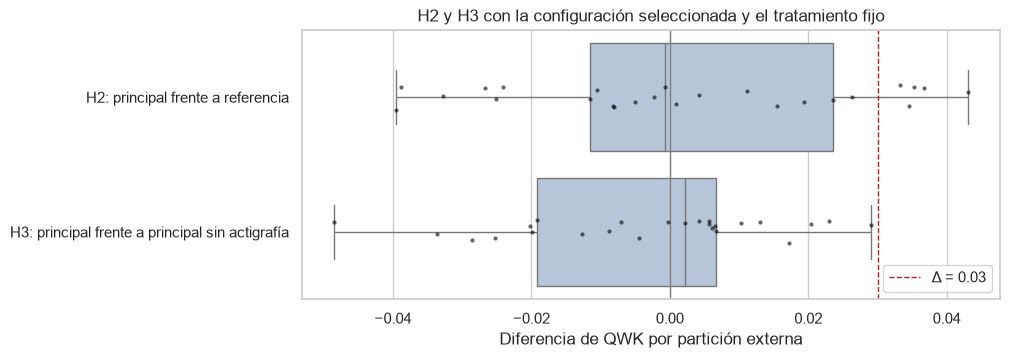

In [33]:
# Diferencias de QWK por partición en H2 y H3, con el cero y la diferencia mínima
# relevante como referencias.
diferencias_figura = pd.concat(
    [
        d[["difference"]].assign(hipótesis=NOMBRES_PRUEBAS[h])
        for h, d in diferencias_hipotesis.items()
    ],
    ignore_index=True,
)
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(
    data=diferencias_figura,
    x="difference",
    y="hipótesis",
    color="lightsteelblue",
    showfliers=False,
    ax=ax,
)
sns.stripplot(
    data=diferencias_figura,
    x="difference",
    y="hipótesis",
    color="black",
    size=3,
    alpha=0.6,
    ax=ax,
)
ax.axvline(0, color="grey", linestyle="-", linewidth=1)
ax.axvline(
    MINIMUM_RELEVANT_QWK_DIFFERENCE,
    color="firebrick",
    linestyle="--",
    linewidth=1,
    label=f"Δ = {MINIMUM_RELEVANT_QWK_DIFFERENCE:g}",
)
ax.set(
    xlabel="Diferencia de QWK por partición externa",
    ylabel="",
    title="H2 y H3 con la configuración seleccionada y el tratamiento fijo",
)
ax.legend(loc="lower right")
save_figure(fig, "diferencias_h2_h3", FIGURAS)
plt.show()

### Conclusión

- **Desempeño de los tres conjuntos.** Con el tratamiento fijo (imputación iterativa y $\alpha = 0{,}5$), el QWK casi no cambia entre conjuntos: 0,369 con el principal, 0,367 con la referencia y 0,372 con el principal sin actigrafía. El conjunto principal con el tratamiento fijo queda muy cerca del obtenido con el tratamiento elegido en cada partición (0,365), así que fijar el tratamiento no cambia el desempeño de la configuración.
- **H2 (principal frente a referencia).** La diferencia media es de 0,002, y el conjunto principal mejora en 12 de las 25 particiones. No hay evidencia de mejora (valor p ajustado de 0,883). El límite superior unilateral del 95 % (0,025) queda por debajo de $\Delta = 0{,}03$, así que el aporte de las variables físicas sobre la edad, el sexo y la temporada de inscripción es despreciable (valor p ajustado de 0,025).
- **H3 (principal frente a principal sin actigrafía).** La diferencia media es de −0,003, con mejora en 13 de 25 particiones. Tampoco hay evidencia de mejora (valor p ajustado de 0,883), y el aporte de la actigrafía es despreciable: el límite superior es 0,014 y el valor p ajustado, 0,004.
- **Por nivel.** El recall severo es 0 con los tres conjuntos. Como dato descriptivo, sin prueba formal, la referencia tiene una tasa de subestimación de los niveles moderado y severo algo menor (0,636) que el conjunto principal (0,687).

Los experimentos iniciales no encontraron evidencia de mejora para H2 ni H3, y la búsqueda completa no la cambia. Con la diferencia mínima relevante fijada de antemano, ahora sí se puede concluir algo más: con la configuración seleccionada, el aporte de los indicadores físicos y de la actigrafía al QWK es menor que 0,03. En H2, el límite superior está cerca del margen, así que la conclusión depende del valor elegido para $\Delta$. En H3, el resultado vale para los 2.736 participantes, de los que solo el 30 % tiene una serie de actigrafía utilizable. La sección 9 repite la comparación restringida a esa subpoblación.

## 9. Comparación en la subpoblación con actigrafía

Solo el 30 % de los participantes tiene una serie de actigrafía utilizable. En los demás, las variables de actigrafía son faltantes que el modelo imputa. Así, la prueba de H3 sobre los 2.736 participantes no distingue entre dos explicaciones: que la actigrafía no aporte, o que su aporte se diluya por la baja cobertura. Esta sección repite la comparación restringida a los 823 participantes con serie utilizable, sobre los mismos participantes y particiones:

- **Referencia con actigrafía frente a referencia:** aísla el aporte de la actigrafía sobre la edad, el sexo y la temporada de inscripción.
- **Principal frente a principal sin actigrafía:** repite H3 en la subpoblación.

**Protocolo.** Se usa la configuración seleccionada con el mismo tratamiento fijo de la sección 8, y los hiperparámetros del modelo se vuelven a elegir en cada partición. La subpoblación tiene sus propias particiones externas: validación cruzada estratificada por SII con cinco particiones, repetida cinco veces con las mismas semillas.

**Pruebas.** Cada diferencia se contrasta con la prueba t corregida de Nadeau y Bengio, unilateral, con $\alpha = 0{,}05$. Los dos valores p forman una familia y se ajustan con el método de Holm. El límite superior unilateral del 95 % se reporta como descripción de la magnitud posible del aporte.

**Alcance.** La subpoblación es una selección por disponibilidad de la serie, así que las conclusiones se limitan a ella. Además, tiene solo 6 participantes severos, demasiado pocos para interpretar el desempeño en ese nivel.

In [34]:
# Subpoblación con una serie de actigrafía utilizable, con sus propias particiones
# externas: validación cruzada estratificada por SII con cinco particiones,
# repetida cinco veces con las mismas semillas que la búsqueda completa.
analitico_actigrafia = analitico[con_actigrafia].reset_index(drop=True)
y_actigrafia = y[con_actigrafia]
conjuntos_actigrafia = actigraphy_subset_feature_sets(analitico.columns)
particiones_actigrafia = outer_splits(y_actigrafia)

# La referencia con actigrafía agrega a la referencia las mismas variables de
# actigrafía que separan al conjunto principal del principal sin actigrafía.
variables_actigrafia = [
    c
    for c in conjuntos_actigrafia["main"]
    if c not in conjuntos_actigrafia["main_without_actigraphy"]
]
assert conjuntos_actigrafia["reference_with_actigraphy"] == [
    *conjuntos_actigrafia["reference"],
    *variables_actigrafia,
]

print(
    f"Participantes: {len(y_actigrafia)}; "
    f"variables de actigrafía: {', '.join(variables_actigrafia)}"
)
casos_por_particion_actigrafia = split_level_counts(
    particiones_actigrafia, y_actigrafia
).rename(columns=NIVELES_SII)
display(
    pd.Series(y_actigrafia)
    .map(NIVELES_SII)
    .value_counts()
    .reindex(NIVELES_SII.values())
    .rename_axis("SII")
    .to_frame("participantes")
)
# Rango de casos de cada nivel en las 25 particiones de evaluación.
casos_por_particion_actigrafia.agg(["min", "max"]).rename_axis("casos por partición")

Participantes: 823; variables de actigrafía: Actigraphy-ENMO_Day, Actigraphy-ENMO_Night, Actigraphy-Wear_Hours


,participantes
SII,
ninguno,491
leve,221
moderado,105
severo,6


,ninguno,leve,moderado,severo
casos por partición,,,,
min,98,44,21,1
max,99,45,21,2


In [35]:
# Configuración seleccionada con el mismo tratamiento fijo de la sección 8, en los
# cuatro conjuntos de la subpoblación. El sufijo del nombre separa estas
# evaluaciones de las de la sección 8, que usan los mismos conjuntos con todos
# los participantes.
CONJUNTOS_SUBPOBLACION = (
    "reference",
    "reference_with_actigraphy",
    "main_without_actigraphy",
    "main",
)
tareas_actigrafia = {
    conjunto: make_search_task(
        *SELECCIONADA,
        conjunto,
        analitico_actigrafia[conjuntos_actigrafia[conjunto]],
        y_actigrafia,
        particiones_actigrafia,
        cut_level=NIVEL_RECORTE,
        max_iter_factor=FACTOR_ITERACIONES[SELECCIONADA],
        memory=str(CARPETA_MEMORIA),
        grid_extension=AMPLIACIONES.get(SELECCIONADA),
        fixed_params=TRATAMIENTO_FIJO,
        name_suffix=("__extended" if SELECCIONADA in AMPLIACIONES else "")
        + "__fixed__actigraphy_subset",
    )
    for conjunto in CONJUNTOS_SUBPOBLACION
}

inicio = time.perf_counter()
resultados_por_nombre = run_configurations_cached(
    list(tareas_actigrafia.values()),
    cache_dir=CARPETA_CACHE,
    n_jobs=procesos_e2[grupo_seleccionada],
    force=RECALCULAR,
    verbose=5,
)
minutos_actigrafia = (time.perf_counter() - inicio) / 60
resultados_actigrafia = {
    conjunto: resultados_por_nombre[tarea.name]
    for conjunto, tarea in tareas_actigrafia.items()
}
print(f"Minutos en esta ejecución: {minutos_actigrafia:.1f}")
for conjunto, resultado in resultados_actigrafia.items():
    conteo = resultado.counts()
    print(
        f"{NOMBRES_CONJUNTOS[conjunto]}: {conteo['loaded']} particiones cargadas, "
        f"{conteo['computed']} calculadas"
    )

desempeno_actigrafia = pd.DataFrame(
    {
        NOMBRES_CONJUNTOS[conjunto]: {
            "predictores": len(conjuntos_actigrafia[conjunto]),
            **resumen_desempeno(resultado.folds, resultado.predictions),
        }
        for conjunto, resultado in resultados_actigrafia.items()
    }
).T.rename_axis("conjunto")
desempeno_actigrafia["predictores"] = desempeno_actigrafia["predictores"].astype(int)
desempeno_actigrafia.round(3)

Minutos en esta ejecución: 0.0
referencia: 25 particiones cargadas, 0 calculadas
referencia con actigrafía: 25 particiones cargadas, 0 calculadas
principal sin actigrafía: 25 particiones cargadas, 0 calculadas
principal: 25 particiones cargadas, 0 calculadas


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


,predictores,QWK,QWK (desviación entre repeticiones),QWK mínimo por partición,QWK máximo por partición,recall ninguno,recall leve,recall moderado,recall severo,subestimación moderado o severo
conjunto,,,,,,,,,,
referencia,3,0.330,0.022,0.196,0.485,0.635,0.462,0.301,0.0,0.708
referencia con actigrafía,6,0.352,0.009,0.244,0.516,0.619,0.539,0.204,0.0,0.760
principal sin actigrafía,33,0.314,0.016,0.191,0.464,0.628,0.399,0.320,0.0,0.690
principal,36,0.330,0.018,0.236,0.439,0.618,0.452,0.282,0.0,0.719


In [36]:
# Aporte de la actigrafía en la subpoblación: sobre la referencia y sobre el
# conjunto principal. Diferencias de QWK por partición, sobre los mismos
# participantes, con la prueba t corregida unilateral y Holm en la familia.
COMPARACIONES_ACTIGRAFIA = {
    "reference_with_actigraphy_vs_reference": (
        "reference_with_actigraphy",
        "reference",
    ),
    "main_vs_main_without_actigraphy": ("main", "main_without_actigraphy"),
}
assert set(COMPARACIONES_ACTIGRAFIA) == set(HOLM_FAMILIES["actigraphy_subset"])

filas = {}
for comparacion, (conjunto_a, conjunto_b) in COMPARACIONES_ACTIGRAFIA.items():
    diferencias = paired_differences(
        resultados_actigrafia[conjunto_a].folds, resultados_actigrafia[conjunto_b].folds
    )
    superioridad = summarize_paired(diferencias)
    # Límite superior unilateral del 95 % de la diferencia, como descripción.
    limite = negligibility_test(diferencias, MINIMUM_RELEVANT_QWK_DIFFERENCE)
    filas[comparacion] = {
        "diferencia media de QWK": superioridad["mean_difference"],
        "desviación de la diferencia": superioridad["std_difference"],
        "particiones con mejora": superioridad["folds_improved"],
        "t corregido": superioridad["corrected_t"],
        "valor p (unilateral)": superioridad["p_value_one_sided"],
        "límite superior unilateral del 95 %": limite["upper_bound"],
    }
pruebas_actigrafia = pd.DataFrame(filas).T
pruebas_actigrafia["particiones con mejora"] = pruebas_actigrafia[
    "particiones con mejora"
].astype(int)
pruebas_actigrafia["valor p ajustado (Holm)"] = holm_adjust(
    pruebas_actigrafia["valor p (unilateral)"].to_dict()
)
pruebas_actigrafia.rename(index=NOMBRES_PRUEBAS).rename_axis("comparación").round(3)

,diferencia media de QWK,desviación de la diferencia,particiones con mejora,t corregido,valor p (unilateral),límite superior unilateral del 95 %,valor p ajustado (Holm)
comparación,,,,,,,
referencia con actigrafía frente a referencia,0.022,0.060,16,0.667,0.256,0.077,0.511
principal frente a principal sin actigrafía,0.016,0.046,19,0.642,0.263,0.058,0.511


### Conclusión

- **Subpoblación.** Tiene 823 participantes: 491 en el nivel ninguno, 221 en leve, 105 en moderado y 6 en severo. Cada partición de evaluación tiene solo 1 o 2 casos severos. Por eso, algunos ajustes de los umbrales quedan con 2 severos en sus tres particiones internas, y scikit-learn lo advierte durante la ejecución. Esos casos siguen dentro del ajuste, pero el umbral del nivel severo se estima con muy poca información. El recall severo es 0 en los cuatro conjuntos y no se interpreta.
- **Desempeño.** El QWK es más bajo y más variable que con todos los participantes: va de 0,314 a 0,352 entre conjuntos, con particiones entre 0,19 y 0,52. Las dos cifras no son comparables directamente, porque la subpoblación es más pequeña y casi no tiene casos severos.
- **Aporte de la actigrafía.** En esta subpoblación, las dos diferencias son positivas: 0,022 al agregar la actigrafía a la referencia (mejora en 16 de 25 particiones) y 0,016 al agregarla al conjunto principal (mejora en 19 de 25). Ninguna es significativa (valor p ajustado de 0,511 en ambas).
- **Magnitud posible.** Los límites superiores unilaterales del 95 % son 0,077 y 0,058. Ambos superan $\Delta = 0{,}03$, así que, a diferencia de H3 con todos los participantes, aquí no se puede afirmar que el aporte sea despreciable. Con 823 participantes, la diferencia por partición varía más (desviación de 0,046 a 0,060), y la comparación tiene poca potencia.
- **Por nivel.** Como dato descriptivo, la referencia con actigrafía mejora el recall del nivel leve (0,539 frente a 0,462) y empeora el del moderado (0,204 frente a 0,301). Así, su tasa de subestimación de los niveles moderado y severo es mayor (0,760 frente a 0,708).

En los participantes con serie utilizable, la actigrafía muestra un aporte positivo pero no significativo, de una magnitud que esta subpoblación no permite descartar ni confirmar. Este resultado es compatible con la explicación de la cobertura: un aporte que existe solo donde hay serie se diluye entre los 2.736 participantes. Pero no la demuestra. Estas conclusiones se limitan a la subpoblación, que es una selección por disponibilidad de la serie.

## 10. Configuración guardada y conclusiones

Esta sección deja los resultados del notebook listos para el análisis del modelo seleccionado (notebook 04) y para la comparación con el conjunto complementario (notebook 05), sin que esos notebooks tengan que repetir la búsqueda:

- **Modelos de la configuración seleccionada.** Se guarda el modelo ajustado en cada una de las 25 particiones externas, para analizar la contribución de las variables y su estabilidad entre repeticiones. Es la misma evaluación de la selección, con los mismos hiperparámetros elegidos en cada partición. Se guarda aparte, y se verifica que reproduce exactamente sus predicciones.
- **Registro de la configuración.** Un archivo JSON identifica cada evaluación por su nombre en el caché, su configuración y el hash de su firma. Cubre la configuración seleccionada, sus evaluaciones con el tratamiento fijo y las de la subpoblación con actigrafía. Así, los notebooks posteriores reconstruyen exactamente la misma evaluación y cargan sus resultados del caché. Por ejemplo, el notebook 05 evalúa el conjunto complementario con el mismo protocolo que el principal de la sección 8. El registro no contiene datos de los participantes.
- **Tablas para el informe.** Las tablas agregadas del notebook se guardan en CSV. Ninguna tiene filas por participante.

Los modelos ajustados y las predicciones por participante quedan en el caché de evaluaciones, que no se versiona. Al final se libera el caché del preprocesamiento, que solo servía para acelerar los ajustes.

In [37]:
# Modelos ajustados de la configuración seleccionada en cada partición externa,
# para el análisis de interpretabilidad del notebook 04. Es la misma evaluación de
# la selección, con la misma firma, guardada aparte con los modelos.
tarea_modelos = replace(
    tareas_finales[SELECCIONADA],
    name=tareas_finales[SELECCIONADA].name + "__models",
    keep_estimators=True,
)
inicio = time.perf_counter()
resultado_modelos = run_configurations_cached(
    [tarea_modelos],
    cache_dir=CARPETA_CACHE,
    n_jobs=procesos_e2[grupo_seleccionada],
    force=RECALCULAR,
    verbose=5,
)[tarea_modelos.name]
print(f"Minutos en esta ejecución: {(time.perf_counter() - inicio) / 60:.1f}")
print(
    f"Particiones cargadas: {resultado_modelos.counts()['loaded']}; "
    f"calculadas: {resultado_modelos.counts()['computed']}"
)

# El reajuste reproduce la evaluación de la selección: mismos hiperparámetros,
# QWK y predicciones en cada partición.
assert all(m is not None for m in resultado_modelos.estimators.values())
assert list(resultado_modelos.folds["best_params"]) == list(
    seleccionada.folds["best_params"]
)
assert np.allclose(resultado_modelos.folds["qwk"], seleccionada.folds["qwk"])
pd.testing.assert_frame_equal(
    resultado_modelos.predictions.reset_index(drop=True),
    seleccionada.predictions.reset_index(drop=True),
)
print("Los modelos reproducen las predicciones de la selección en las 25 particiones.")

Minutos en esta ejecución: 0.0
Particiones cargadas: 25; calculadas: 0
Los modelos reproducen las predicciones de la selección en las 25 particiones.


[Parallel(n_jobs=13)]: Using backend LokyBackend with 13 concurrent workers.


In [38]:
# Registro de la configuración seleccionada para los notebooks 04 y 05: cada
# evaluación se identifica por su nombre en el caché, su configuración y el hash
# de su firma, de modo que esos notebooks la reconstruyen y cargan sus
# particiones sin volver a ajustarlas. Solo contiene parámetros, hashes y
# resultados agregados.
sufijo = "__extended" if SELECCIONADA in AMPLIACIONES else ""
registro = {
    "selected": {
        "evaluation": task_entry(tarea_modelos, sufijo + "__models"),
        "grid": "extended" if SELECCIONADA in AMPLIACIONES else "original",
        "most_frequent_strategy": estrategia_frecuente[SELECCIONADA],
        "mean_qwk": seleccionada.folds["qwk"].mean(),
        "qwk_sd_between_repeats": por_repeticion["QWK"].std(),
        "underestimation_moderate_or_severe": por_repeticion[
            "subestimación moderado o severo"
        ].mean(),
        "severe_recall": aciertos_severo["recall"].mean(),
        "severe_recall_unstable": SEVERO_INESTABLE,
    },
    "fixed_treatment": TRATAMIENTO_FIJO,
    "fixed_treatment_evaluations": {
        conjunto: task_entry(tarea, sufijo + "__fixed")
        for conjunto, tarea in tareas_hipotesis.items()
    },
    "actigraphy_subset_evaluations": {
        conjunto: task_entry(tarea, sufijo + "__fixed__actigraphy_subset")
        for conjunto, tarea in tareas_actigrafia.items()
    },
    "hypotheses": pruebas_hipotesis["conclusión"].to_dict(),
    "validation": {
        "outer_repeats": N_OUTER_REPEATS,
        "outer_splits": N_OUTER_SPLITS,
        "inner_splits": N_INNER_SPLITS,
        "random_seed": RANDOM_SEED,
        "cut_level": NIVEL_RECORTE,
        "cache_version": CACHE_VERSION,
    },
}
ruta_registro = save_record(registro)
print(f"Registro guardado en {ruta_registro.relative_to(PROJECT_ROOT)}")
registro["selected"]["evaluation"]

Registro guardado en models/selected_configuration.json


{'name': 'linear__threshold_regression__main__c0__i1__models',
 'signature': '7ded0540ac9e1322b70cd9c71318df73285fd3d9f09bfcd7f2e54c8ae4a386a3',
 'config': {'algorithm': 'linear',
  'cut_level': 0,
  'feature_set': 'main',
  'formulation': 'threshold_regression',
  'max_iter_factor': 1},
 'name_suffix': '__models'}

In [39]:
# Tablas agregadas del notebook, para el informe, con los mismos nombres que se
# muestran en el notebook: ninguna contiene filas por participante.
CARPETA_TABLAS = TABLES_DIR / "03_busqueda_modelos"
TABLAS = {
    "diseno_busqueda": diseno_busqueda,
    "costo_primera_repeticion": costo_e1,
    "desempeno_controles": desempeno_controles,
    "desempeno_busqueda_completa": desempeno_e2,
    "tratamiento_elegido": tratamiento_elegido,
    "revision_bordes": revision_bordes,
    "comparacion_grillas_ampliadas": comparacion_grillas,
    "seleccion": tabla_seleccion,
    "seleccionada_por_repeticion": pd.concat(
        [por_repeticion, resumen_repeticiones]
    ).rename_axis("repetición"),
    "seleccionada_aciertos_severo": aciertos_severo.rename(
        columns={
            "cases": "casos severos",
            "hits": "aciertos",
            "recall": "recall",
            "wilson_low": "Wilson inferior",
            "wilson_high": "Wilson superior",
        }
    ).rename_axis("repetición"),
    "seleccionada_distribucion_severo": distribucion_severo.to_frame(
        "proporción de los casos severos"
    ).rename_axis("nivel asignado"),
    "comparacion_severo": comparacion_severo,
    "desempeno_h2_h3": desempeno_hipotesis,
    "pruebas_h2_h3": pruebas_hipotesis.rename(index=NOMBRES_PRUEBAS).rename_axis(
        "hipótesis"
    ),
    "desempeno_subpoblacion_actigrafia": desempeno_actigrafia,
    "pruebas_subpoblacion_actigrafia": pruebas_actigrafia.rename(
        index=NOMBRES_PRUEBAS
    ).rename_axis("comparación"),
}
# Control de privacidad: ninguna tabla tiene columnas de identificación o de
# posición de participantes, y todas son pequeñas, como corresponde a resúmenes.
for nombre, tabla in TABLAS.items():
    columnas = {str(c).lower() for c in [*tabla.columns, *tabla.index.names]}
    assert not columnas & {"id", "position", "posición"}, nombre
    assert len(tabla) < 100, nombre

CARPETA_TABLAS.mkdir(parents=True, exist_ok=True)
for nombre, tabla in TABLAS.items():
    tabla.to_csv(CARPETA_TABLAS / f"{nombre}.csv")
print(f"{len(TABLAS)} tablas guardadas en {CARPETA_TABLAS.relative_to(PROJECT_ROOT)}")

16 tablas guardadas en reports/tables/03_busqueda_modelos


In [40]:
# El caché de Pipeline(memory=...) solo acelera los ajustes: los resultados y los
# modelos quedan en el caché de evaluaciones. Se libera al terminar.
clear_pipeline_memory(CARPETA_MEMORIA)
print(f"Caché de evaluaciones: {directory_size(CARPETA_CACHE) / 1e9:.2f} GB")

Caché de evaluaciones: 0.13 GB


### Conclusión

Este notebook desarrolló el objetivo específico 2: comparó doce configuraciones —cuatro algoritmos por tres formulaciones del SII— con validación cruzada anidada y el QWK, y las contrastó con un modelo de referencia demográfico.

- **Búsqueda.** Todas las configuraciones aprenden de los predictores: su QWK medio va de 0,260 a 0,367, frente a un control aleatorio cuyo máximo por partición es 0,082. La formulación pesa más que el algoritmo. Las cuatro regresiones con umbrales ocupan los primeros lugares, y Frank y Hall, los últimos.
- **Configuración seleccionada.** Es el modelo lineal regularizado (elastic net) con regresión con umbrales, imputación iterativa y $\alpha = 0{,}5$ en la mayoría de las particiones. Su QWK medio es 0,365, con una desviación entre repeticiones de 0,007 y un sesgo optimista por haberse usado para elegirla. Las otras tres regresiones con umbrales no difieren significativamente de ella, y el empate se resolvió por la menor tasa de subestimación y por la menor complejidad.
- **Nivel severo.** La configuración no detecta ninguno de los 34 casos severos en ninguna repetición; la mayoría se asigna al nivel moderado. Los mejores modelos de los otros algoritmos tampoco los detectan. Frank y Hall sí alcanzaba un recall severo alto, a cambio de un QWK menor. Este contraste entre el QWK y la detección de los casos más graves es la principal tensión del problema.
- **H2 y H3.** Con la configuración seleccionada y la diferencia mínima relevante fijada de antemano, el aporte de los indicadores físicos sobre la edad, el sexo y la temporada de inscripción es despreciable, y también el de la actigrafía sobre el resto del conjunto principal.
- **Subpoblación con actigrafía.** En los 823 participantes con serie utilizable, la actigrafía muestra un aporte positivo pero no significativo, y la potencia no alcanza para descartar un aporte relevante.

En conjunto, los indicadores de actividad y aptitud física no mejoran la estimación del SII frente a un modelo con variables demográficas, al menos con los algoritmos y formulaciones evaluados. Todas las configuraciones alcanzan un acuerdo moderado con el SII y casi no detectan los casos severos.

La configuración seleccionada, sus modelos por partición y sus evaluaciones con el tratamiento fijo quedan registrados. Así, el análisis por nivel, el tamizaje, la interpretabilidad y los errores por sexo y edad (objetivo 3), y la comparación con el conjunto complementario (objetivo 4) se hacen con exactamente las mismas evaluaciones.